# v19.5 Global Soil Moisture — Full Error Analysis & Visualization

This notebook compares the two completed v19.5 models:

- **`location_history`** — environmental features plus station/location history.
- **`environment_only`** — environmental features without location-history inputs.

It reads the already-exported train/test Parquet predictions from the two extracted folders in `UG_SM`. It **does not retrain either model and does not rerun model inference**. DuckDB performs full-table metrics and grouped analyses directly against Parquet; only bounded samples are brought into pandas for plots.

The analysis includes overall and matched-observation comparisons, density-based prediction diagnostics, fine station maps split into geographic regions, temporal anomaly investigation (including the late-2025 window), and a transparent high-error-trimming sensitivity analysis for R².

**Important interpretation:** removing the worst errors is a post-hoc sensitivity test, not a legitimate way to improve or report the model's operational score. The notebook reports how much data is discarded and how many observations remain. Likewise, a temporal association is not proof of a cause; diagnosing a late-2025 spike requires checking station/network mix, target distribution, data quality, and (ideally) the underlying environmental inputs.

Run all cells from top to bottom with this notebook located in `UG_SM` alongside the two extracted export folders. See the README for packages and output locations.


In [1]:
# 1. Imports and user settings
from pathlib import Path
import json, math, textwrap, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

try:
    import duckdb
except ImportError as exc:
    raise ImportError(
        "DuckDB is required for memory-conscious analysis. Install it with: "
        "python -m pip install duckdb"
    ) from exc

# Usually the notebook is opened with UG_SM as the working directory.
BASE_DIR = Path.cwd().resolve()
LOCATION_DIR_NAME = "error_analysis_export_v19_5_location_history"
ENVIRONMENT_DIR_NAME = "error_analysis_export_v19_5_environment_only"

# Keep station summaries from becoming noisy. Lower this to include smaller stations.
MIN_STATION_ROWS = 10
# Max rows pulled into pandas for scatter/histogram plots (aggregations still use all rows).
PLOT_SAMPLE_PER_SPLIT = 60000
# Approximate global grid size for spatial error summaries, in degrees.
SPATIAL_GRID_DEGREES = 2.0
# Optional: set a DuckDB memory cap such as "6GB". None lets DuckDB use its default.
DUCKDB_MEMORY_LIMIT = None

# Temporal anomaly investigation window. These dates are intentionally editable.
# The supplied monthly plot suggests inspecting Sep-Nov 2025, centred on the visible spike.
EVENT_WINDOW_START = pd.Timestamp("2025-09-01")
EVENT_WINDOW_END = pd.Timestamp("2025-11-30")  # inclusive
AUTO_ANOMALY_MAD_MULTIPLIER = 2.5
MIN_MONTH_ROWS = 20

# High-error trimming sensitivity. We rank test rows by absolute error, remove the
# largest errors first, and recompute R² on the retained rows. This is diagnostic only.
TRIM_TARGET_R2S = [0.70, 0.80, 0.90]
TRIM_CURVE_BINS = 1000            # approximately 0.1 percentage-point resolution
TRIM_MAX_REMOVAL_PCT = 95.0       # never report a score based on fewer than 5% of rows
TRIM_MIN_RETAINED_ROWS = 100

OUTPUT_DIR = BASE_DIR / "error_analysis_results_v19_5"
PLOTS_DIR = OUTPUT_DIR / "plots"
TABLES_DIR = OUTPUT_DIR / "tables"
for _p in (OUTPUT_DIR, PLOTS_DIR, TABLES_DIR):
    _p.mkdir(parents=True, exist_ok=True)

print("Working directory:", BASE_DIR)
print("Analysis outputs:", OUTPUT_DIR)
# Optional mapping dependency for country borders: conda install -c conda-forge cartopy


Working directory: /home/mayur/Code/UG_SM
Analysis outputs: /home/mayur/Code/UG_SM/error_analysis_results_v19_5


In [2]:
# 2. Locate and validate both export directories

def locate_export_dir(folder_name: str) -> Path:
    direct = BASE_DIR / folder_name
    if (direct / "predictions" / "train_predictions.parquet").is_file():
        return direct
    # Handles the common case where the archive was extracted one directory deeper.
    matches = []
    # Search only one directory level down; avoid crawling the large model/cache tree.
    for candidate in BASE_DIR.glob(f"*/{folder_name}"):
        if (candidate / "predictions" / "train_predictions.parquet").is_file():
            matches.append(candidate)
    if len(matches) == 1:
        return matches[0]
    if len(matches) > 1:
        raise RuntimeError(
            f"Found multiple valid {folder_name} directories:\n" +
            "\n".join(str(x) for x in matches) +
            "\nSet the corresponding *_EXPORT_DIR variable manually in this cell."
        )
    raise FileNotFoundError(
        f"Could not find {folder_name}/predictions/train_predictions.parquet.\n"
        f"Expected it under {BASE_DIR}. Move this notebook into UG_SM or edit BASE_DIR."
    )

LOCATION_EXPORT_DIR = locate_export_dir(LOCATION_DIR_NAME)
ENVIRONMENT_EXPORT_DIR = locate_export_dir(ENVIRONMENT_DIR_NAME)
EXPORT_DIRS = {
    "location_history": LOCATION_EXPORT_DIR,
    "environment_only": ENVIRONMENT_EXPORT_DIR,
}

for mode, folder in EXPORT_DIRS.items():
    print(f"\n{mode}: {folder}")
    for required in [
        folder / "predictions" / "train_predictions.parquet",
        folder / "predictions" / "test_predictions.parquet",
        folder / "model_config.json",
        folder / "final_metrics.json",
    ]:
        if not required.is_file():
            raise FileNotFoundError(f"Required export file missing for {mode}: {required}")
    cfg = json.loads((folder / "model_config.json").read_text(encoding="utf-8"))
    print("  target_mode:", cfg.get("target_mode"), "| backbone:", cfg.get("temporal_backbone"))
    for split in ("train", "test"):
        f = folder / "predictions" / f"{split}_predictions.parquet"
        print(f"  {split:5s}: {f.stat().st_size / (1024**3):.3f} GiB")

# Check that both exports describe the same target definition.
CONFIGS = {m: json.loads((p / "model_config.json").read_text(encoding="utf-8"))
           for m, p in EXPORT_DIRS.items()}
if CONFIGS["location_history"].get("target_mode") != CONFIGS["environment_only"].get("target_mode"):
    raise ValueError("The exports use different target_mode values; comparing their scores would not be valid.")
TARGET_MODE = CONFIGS["location_history"].get("target_mode")
print("\nShared target_mode:", TARGET_MODE)


location_history: /home/mayur/Code/UG_SM/error_analysis_export_v19_5_location_history
  target_mode: direct | backbone: tcn
  train: 0.164 GiB
  test : 0.075 GiB

environment_only: /home/mayur/Code/UG_SM/error_analysis_export_v19_5_environment_only
  target_mode: direct | backbone: tcn
  train: 0.182 GiB
  test : 0.053 GiB

Shared target_mode: direct


In [3]:
# 3. Open prediction Parquet files as DuckDB views (no full-table pandas load)
DB = duckdb.connect(database=":memory:")
DB.execute("SET threads = 4")
DUCKDB_TEMP_DIR = OUTPUT_DIR / "duckdb_tmp"
DUCKDB_TEMP_DIR.mkdir(parents=True, exist_ok=True)
DB.execute(f"SET temp_directory = '{DUCKDB_TEMP_DIR.as_posix().replace(chr(39), chr(39)*2)}'")
if DUCKDB_MEMORY_LIMIT:
    DB.execute(f"SET memory_limit = '{DUCKDB_MEMORY_LIMIT}'")


def sql_string(value: str) -> str:
    return "'" + str(value).replace("'", "''") + "'"

VIEWS = {}
for mode, folder in EXPORT_DIRS.items():
    for split in ("train", "test"):
        view = f"{ 'lh' if mode == 'location_history' else 'eo' }_{split}"
        parquet_path = folder / "predictions" / f"{split}_predictions.parquet"
        DB.execute(f"CREATE OR REPLACE VIEW {view} AS SELECT * FROM read_parquet({sql_string(parquet_path.as_posix())})")
        VIEWS[(mode, split)] = view

REQUIRED_COLUMNS = {
    "sample_id", "network", "station_id", "station_key", "sample_date",
    "latitude", "longitude", "y_true_m3_m3", "prediction_m3_m3",
    "raw_prediction_m3_m3", "anchor_smap_m3_m3", "residual_m3_m3",
    "absolute_error_m3_m3", "squared_error_m3_m6", "raw_residual_m3_m3",
}
SCHEMAS = {}
for (mode, split), view in VIEWS.items():
    cols = {r[0] for r in DB.execute(f"DESCRIBE {view}").fetchall()}
    SCHEMAS[(mode, split)] = cols
    missing = sorted(REQUIRED_COLUMNS - cols)
    if missing:
        raise ValueError(f"{mode}/{split} prediction file is missing required columns: {missing}")
    n_rows, n_stations, d0, d1 = DB.execute(
        f"SELECT COUNT(*), COUNT(DISTINCT station_key), MIN(CAST(sample_date AS DATE)), "
        f"MAX(CAST(sample_date AS DATE)) FROM {view}"
    ).fetchone()
    print(f"{mode:17s} {split:5s}: {n_rows:>12,} rows | {n_stations:>7,} stations | {d0} to {d1}")

# A compact schema report makes it easy to audit exactly what was exported.
schema_report = []
for (mode, split), cols in SCHEMAS.items():
    schema_report.append({"task_mode": mode, "split": split, "columns": len(cols),
                          "has_SMAP": "SMAP" in cols, "has_target_quality_fields": "target_std_m3_m3" in cols})
schema_report = pd.DataFrame(schema_report)
display(schema_report)

location_history  train:    2,216,784 rows |   2,100 stations | 2015-04-01 to 2022-12-31
location_history  test :      905,248 rows |   1,028 stations | 2023-01-01 to 2026-10-03
environment_only  train:    2,544,038 rows |   1,758 stations | 2015-04-01 to 2026-10-03
environment_only  test :      644,716 rows |     444 stations | 2015-04-01 to 2026-10-03


,task_mode,split,columns,has_SMAP,has_target_quality_fields
0,location_history,train,32,True,True
1,location_history,test,32,True,True
2,environment_only,train,32,True,True
3,environment_only,test,32,True,True


## 1) Data and export integrity

The export code wrote `source_row_index` and verified that each model-loader target agrees with the corresponding manifest target before finalizing each Parquet file. This section performs independent checks on the local files: prediction counts, duplicate sample keys, missing numerical values, train/test date coverage, and the recorded-versus-recomputed metrics.

In [4]:
# 4. Row-level integrity checks and export metadata comparison
integrity_rows = []
for (mode, split), view in VIEWS.items():
    row = DB.execute(f"""
        SELECT
          COUNT(*) AS n_rows,
          COUNT(DISTINCT sample_id) AS n_distinct_sample_id,
          COUNT(DISTINCT station_key) AS n_stations,
          SUM(CASE WHEN y_true_m3_m3 IS NULL OR NOT isfinite(y_true_m3_m3) THEN 1 ELSE 0 END) AS bad_y,
          SUM(CASE WHEN prediction_m3_m3 IS NULL OR NOT isfinite(prediction_m3_m3) THEN 1 ELSE 0 END) AS bad_prediction,
          SUM(CASE WHEN residual_m3_m3 IS NULL OR NOT isfinite(residual_m3_m3) THEN 1 ELSE 0 END) AS bad_residual,
          SUM(CASE WHEN ABS((prediction_m3_m3 - y_true_m3_m3) - residual_m3_m3) > 1e-5 THEN 1 ELSE 0 END) AS residual_formula_mismatch,
          SUM(CASE WHEN ABS(ABS(residual_m3_m3) - absolute_error_m3_m3) > 1e-5 THEN 1 ELSE 0 END) AS abs_error_formula_mismatch,
          MIN(CAST(sample_date AS DATE)) AS min_date,
          MAX(CAST(sample_date AS DATE)) AS max_date
        FROM {view}
    """).df().iloc[0].to_dict()
    row.update(task_mode=mode, split=split)
    integrity_rows.append(row)
INTEGRITY = pd.DataFrame(integrity_rows)[[
    "task_mode", "split", "n_rows", "n_distinct_sample_id", "n_stations",
    "bad_y", "bad_prediction", "bad_residual", "residual_formula_mismatch",
    "abs_error_formula_mismatch", "min_date", "max_date"
]]
display(INTEGRITY)
INTEGRITY.to_csv(TABLES_DIR / "integrity_checks.csv", index=False)

if (INTEGRITY[["bad_y", "bad_prediction", "bad_residual", "residual_formula_mismatch", "abs_error_formula_mismatch"]].fillna(0).to_numpy() > 0).any():
    warnings.warn("At least one data-integrity check is non-zero. Inspect integrity_checks.csv before interpreting metrics.")

# Compare recomputed full-split metrics to the values written by the export cell.
def load_export_metrics(mode):
    return json.loads((EXPORT_DIRS[mode] / "final_metrics.json").read_text(encoding="utf-8"))
EXPORT_METRICS = {m: load_export_metrics(m) for m in EXPORT_DIRS}
print("\nCheckpoint metadata")
for mode, cfg in CONFIGS.items():
    print(f"{mode}: best_epoch={cfg.get('best_epoch')}, target_mode={cfg.get('target_mode')}, backbone={cfg.get('temporal_backbone')}")

,task_mode,split,n_rows,n_distinct_sample_id,n_stations,bad_y,bad_prediction,bad_residual,residual_formula_mismatch,abs_error_formula_mismatch,min_date,max_date
0,location_history,train,2216784,2216784,2100,0.0,0.0,0.0,0.0,0.0,2015-04-01,2022-12-31
1,location_history,test,905248,905248,1028,0.0,0.0,0.0,0.0,0.0,2023-01-01,2026-10-03
2,environment_only,train,2544038,2544038,1758,0.0,0.0,0.0,0.0,0.0,2015-04-01,2026-10-03
3,environment_only,test,644716,644716,444,0.0,0.0,0.0,0.0,0.0,2015-04-01,2026-10-03



Checkpoint metadata
location_history: best_epoch=79, target_mode=direct, backbone=tcn
environment_only: best_epoch=13, target_mode=direct, backbone=tcn


## 2) Overall performance — calibrated, raw, and SMAP anchor

For each split, the notebook computes MAE, RMSE, bias, unbiased RMSE, R², Pearson correlation, and sample count. It evaluates the calibrated model output, the raw model output before the learned calibration, and the SMAP anchor baseline where available. Negative bias means systematic underprediction; positive bias means overprediction.

,task_mode,split,variant,n,mae_m3_m3,rmse_m3_m3,ubrmse_m3_m3,bias_m3_m3,r2,pearson_r,mean_observed,mean_predicted
0,environment_only,test,SMAP_anchor,644716.0,0.07868,0.10232,NaN,0.00261,0.25487,0.57423,0.18711,0.18972
1,location_history,test,SMAP_anchor,905248.0,0.08012,0.10905,NaN,0.00175,0.05201,0.48752,0.17749,0.17924
2,environment_only,test,calibrated,644716.0,0.06794,0.08626,0.08617,0.00405,0.47046,0.68686,0.18711,0.19116
3,location_history,test,calibrated,905248.0,0.04854,0.06594,0.06592,0.00123,0.65341,0.81033,0.17749,0.17872
4,environment_only,test,raw,644716.0,0.06844,0.08768,0.08694,-0.01134,0.45288,0.68003,0.18711,0.17577
5,location_history,test,raw,905248.0,0.09228,0.11190,0.08067,-0.07755,0.00182,0.74902,0.17749,0.09994
6,environment_only,train,SMAP_anchor,2544038.0,0.08124,0.11071,NaN,0.00669,0.08514,0.52347,0.18682,0.19351
7,location_history,train,SMAP_anchor,2216784.0,0.08049,0.10847,NaN,0.00698,0.14884,0.54907,0.19079,0.19778
8,environment_only,train,calibrated,2544038.0,0.05892,0.07580,0.07564,0.00497,0.57113,0.75845,0.18682,0.19178
9,location_history,train,calibrated,2216784.0,0.03544,0.04836,0.04836,-0.00065,0.83079,0.91168,0.19079,0.19014


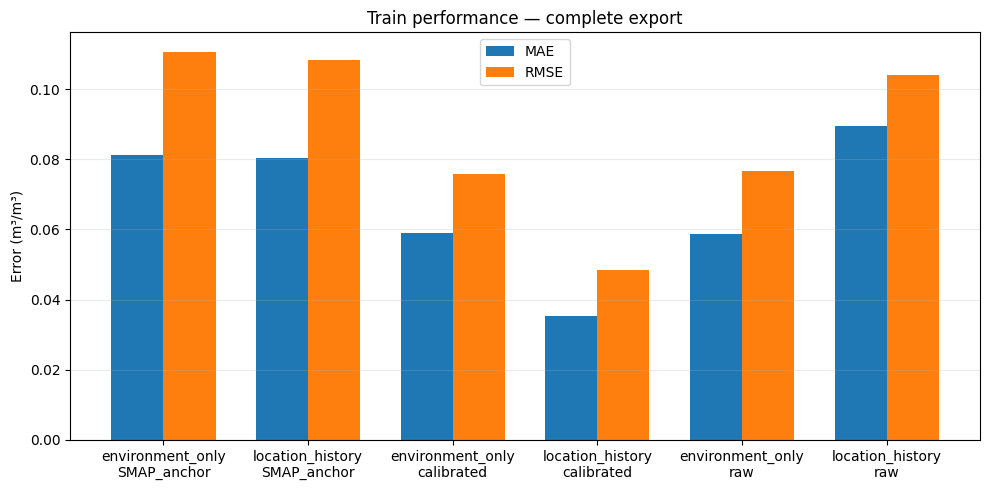

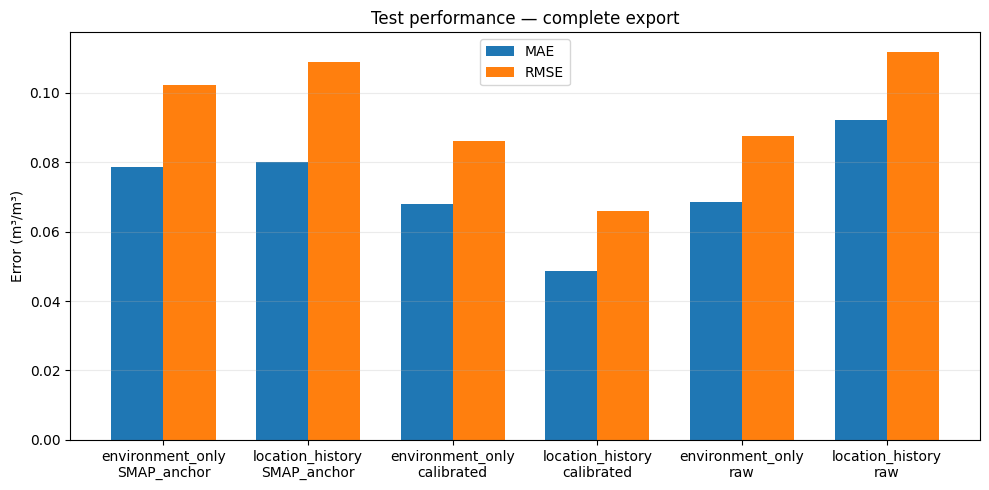

In [5]:
# 5. Metric calculations from complete Parquet scans

def metric_sql(view: str, pred_col: str, residual_col: str):
    return f"""
    SELECT
      COUNT(*)::BIGINT AS n,
      AVG({residual_col}) AS bias_m3_m3,
      AVG(ABS({residual_col})) AS mae_m3_m3,
      SQRT(AVG({residual_col} * {residual_col})) AS rmse_m3_m3,
      SQRT(GREATEST(AVG({residual_col} * {residual_col}) - POWER(AVG({residual_col}), 2), 0)) AS ubrmse_m3_m3,
      CASE WHEN (SUM(y_true_m3_m3*y_true_m3_m3) - SUM(y_true_m3_m3)*SUM(y_true_m3_m3)/COUNT(*)) > 0
           THEN 1.0 - SUM(POWER({residual_col}, 2)) /
                (SUM(y_true_m3_m3*y_true_m3_m3) - SUM(y_true_m3_m3)*SUM(y_true_m3_m3)/COUNT(*))
           ELSE NULL END AS r2,
      CORR(y_true_m3_m3, {pred_col}) AS pearson_r,
      AVG(y_true_m3_m3) AS mean_observed,
      AVG({pred_col}) AS mean_predicted
    FROM {view}
    WHERE y_true_m3_m3 IS NOT NULL AND {pred_col} IS NOT NULL
      AND isfinite(y_true_m3_m3) AND isfinite({pred_col}) AND isfinite({residual_col})
    """

metric_rows = []
for (mode, split), view in VIEWS.items():
    variants = [
        ("calibrated", "prediction_m3_m3", "residual_m3_m3"),
        ("raw", "raw_prediction_m3_m3", "raw_residual_m3_m3"),
    ]
    for variant, pred_col, resid_col in variants:
        result = DB.execute(metric_sql(view, pred_col, resid_col)).df().iloc[0].to_dict()
        result.update(task_mode=mode, split=split, variant=variant)
        metric_rows.append(result)
    anchor_result = DB.execute(f"""
        SELECT COUNT(*)::BIGINT AS n,
               AVG(anchor_smap_m3_m3 - y_true_m3_m3) AS bias_m3_m3,
               AVG(ABS(anchor_smap_m3_m3 - y_true_m3_m3)) AS mae_m3_m3,
               SQRT(AVG(POWER(anchor_smap_m3_m3 - y_true_m3_m3, 2))) AS rmse_m3_m3,
               CASE WHEN VAR_POP(y_true_m3_m3) > 0
                    THEN 1.0 - SUM(POWER(anchor_smap_m3_m3 - y_true_m3_m3, 2)) /
                         (SUM(y_true_m3_m3*y_true_m3_m3) - SUM(y_true_m3_m3)*SUM(y_true_m3_m3)/COUNT(*))
                    ELSE NULL END AS r2,
               CORR(y_true_m3_m3, anchor_smap_m3_m3) AS pearson_r,
               AVG(y_true_m3_m3) AS mean_observed,
               AVG(anchor_smap_m3_m3) AS mean_predicted
        FROM {view}
        WHERE anchor_smap_m3_m3 IS NOT NULL AND isfinite(anchor_smap_m3_m3)
          AND y_true_m3_m3 IS NOT NULL AND isfinite(y_true_m3_m3)
    """).df().iloc[0].to_dict()
    anchor_result["ubrmse_m3_m3"] = np.nan
    anchor_result.update(task_mode=mode, split=split, variant="SMAP_anchor")
    metric_rows.append(anchor_result)

METRICS = pd.DataFrame(metric_rows)[[
    "task_mode", "split", "variant", "n", "mae_m3_m3", "rmse_m3_m3",
    "ubrmse_m3_m3", "bias_m3_m3", "r2", "pearson_r", "mean_observed", "mean_predicted"
]]
METRICS = METRICS.sort_values(["split", "variant", "task_mode"]).reset_index(drop=True)
display(METRICS.round(5))
METRICS.to_csv(TABLES_DIR / "overall_metrics.csv", index=False)

# Plot summary metrics; all metrics above were calculated over the full exports.
for split in ("train", "test"):
    plot_df = METRICS[(METRICS.split == split) & METRICS.variant.isin(["calibrated", "raw", "SMAP_anchor"])]
    fig, ax = plt.subplots(figsize=(10, 5))
    labels = [f"{r.task_mode}\n{r.variant}" for r in plot_df.itertuples()]
    x = np.arange(len(plot_df))
    ax.bar(x - 0.18, plot_df["mae_m3_m3"], width=0.36, label="MAE")
    ax.bar(x + 0.18, plot_df["rmse_m3_m3"], width=0.36, label="RMSE")
    ax.set_xticks(x, labels)
    ax.set_ylabel("Error (m³/m³)")
    ax.set_title(f"{split.title()} performance — complete export")
    ax.legend()
    ax.grid(axis="y", alpha=0.25)
    fig.tight_layout()
    fig.savefig(PLOTS_DIR / f"overall_{split}_mae_rmse.png", dpi=160)
    plt.show()
    plt.close(fig)

## 3) Apples-to-apples comparison on shared observations

The two task modes can have different eligible rows because their input requirements differ. Comparing their full-split scores alone may therefore mix model differences with sample-composition differences.

The paired analysis joins predictions by `network + station_id + sample_date + sample_id` within each split. It reports how many observations overlap, verifies the two target values agree, and compares errors only on the shared observations. A negative `location_minus_environment_mae` or `location_minus_environment_rmse` means the location-history model is better.

,split,location_rows,environment_rows,matched_rows,matched_pct_of_location,matched_pct_of_environment,max_abs_target_difference,mean_abs_target_difference
0,train,2216784,2544038,1768579,79.781296,69.518576,0.0,0.0
1,test,905248,644716,182528,20.163314,28.311381,0.0,0.0


,n,location_mae,location_rmse,location_bias,environment_mae,environment_rmse,environment_bias,location_r2,environment_r2,location_pearson_r,environment_pearson_r,location_minus_environment_mae,mean_squared_error_difference,location_win_pct,tie_pct,split
0,1768579.0,0.035098,0.047884,-0.000108,0.059335,0.076509,0.003983,0.832656,0.572779,0.912649,0.759266,-0.024237,-0.003561,70.111881,0.0,train
1,182528.0,0.049328,0.067041,-0.000638,0.066636,0.084902,0.005556,0.662614,0.458889,0.816187,0.679124,-0.017307,-0.002714,62.617242,0.0,test


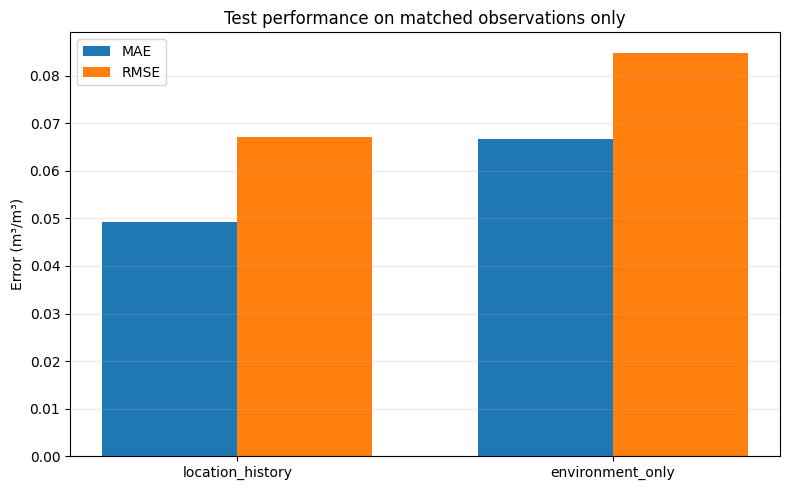

In [6]:
# 6. Build paired views, row overlap diagnostics, and matched-sample metrics
PAIR_KEYS = ["network", "station_id", "sample_date", "sample_id"]
PAIR_VIEWS = {}
pair_overlap_rows = []
paired_metric_rows = []

for split in ("train", "test"):
    lh = VIEWS[("location_history", split)]
    eo = VIEWS[("environment_only", split)]
    pview = f"paired_{split}"
    on_clause = " AND ".join([
        f"CAST(l.{k} AS VARCHAR) = CAST(e.{k} AS VARCHAR)" if k != "sample_date"
        else f"CAST(l.{k} AS DATE) = CAST(e.{k} AS DATE)"
        for k in PAIR_KEYS
    ])
    DB.execute(f"""
      CREATE OR REPLACE VIEW {pview} AS
      SELECT l.network, l.station_id, l.station_key AS location_station_key,
             l.sample_id, CAST(l.sample_date AS DATE) AS sample_date,
             l.latitude, l.longitude,
             l.y_true_m3_m3 AS y_location,
             e.y_true_m3_m3 AS y_environment,
             l.prediction_m3_m3 AS pred_location,
             e.prediction_m3_m3 AS pred_environment,
             l.residual_m3_m3 AS residual_location,
             e.residual_m3_m3 AS residual_environment,
             l.absolute_error_m3_m3 AS abs_error_location,
             e.absolute_error_m3_m3 AS abs_error_environment,
             l.raw_prediction_m3_m3 AS raw_pred_location,
             e.raw_prediction_m3_m3 AS raw_pred_environment,
             l.anchor_smap_m3_m3 AS anchor_location
      FROM {lh} l INNER JOIN {eo} e ON {on_clause}
    """)
    PAIR_VIEWS[split] = pview
    n_lh = DB.execute(f"SELECT COUNT(*) FROM {lh}").fetchone()[0]
    n_eo = DB.execute(f"SELECT COUNT(*) FROM {eo}").fetchone()[0]
    n_pair, target_max_diff, target_mean_diff = DB.execute(f"""
      SELECT COUNT(*), MAX(ABS(y_location-y_environment)), AVG(ABS(y_location-y_environment))
      FROM {pview}
    """).fetchone()
    pair_overlap_rows.append({"split": split, "location_rows": n_lh, "environment_rows": n_eo,
                              "matched_rows": n_pair,
                              "matched_pct_of_location": 100*n_pair/n_lh if n_lh else np.nan,
                              "matched_pct_of_environment": 100*n_pair/n_eo if n_eo else np.nan,
                              "max_abs_target_difference": target_max_diff,
                              "mean_abs_target_difference": target_mean_diff})
    paired = DB.execute(f"""
      SELECT COUNT(*)::BIGINT AS n,
        AVG(abs_error_location) AS location_mae,
        SQRT(AVG(POWER(residual_location,2))) AS location_rmse,
        AVG(residual_location) AS location_bias,
        AVG(abs_error_environment) AS environment_mae,
        SQRT(AVG(POWER(residual_environment,2))) AS environment_rmse,
        AVG(residual_environment) AS environment_bias,
        CASE WHEN (SUM(y_location*y_location)-SUM(y_location)*SUM(y_location)/COUNT(*)) > 0
             THEN 1.0-SUM(POWER(residual_location,2))/(SUM(y_location*y_location)-SUM(y_location)*SUM(y_location)/COUNT(*))
             ELSE NULL END AS location_r2,
        CASE WHEN (SUM(y_environment*y_environment)-SUM(y_environment)*SUM(y_environment)/COUNT(*)) > 0
             THEN 1.0-SUM(POWER(residual_environment,2))/(SUM(y_environment*y_environment)-SUM(y_environment)*SUM(y_environment)/COUNT(*))
             ELSE NULL END AS environment_r2,
        CORR(y_location, pred_location) AS location_pearson_r,
        CORR(y_environment, pred_environment) AS environment_pearson_r,
        AVG(abs_error_location-abs_error_environment) AS location_minus_environment_mae,
        AVG(POWER(residual_location,2)-POWER(residual_environment,2)) AS mean_squared_error_difference,
        100.0*AVG(CASE WHEN abs_error_location < abs_error_environment THEN 1.0 ELSE 0.0 END) AS location_win_pct,
        100.0*AVG(CASE WHEN abs_error_location = abs_error_environment THEN 1.0 ELSE 0.0 END) AS tie_pct
      FROM {pview}
      WHERE y_location IS NOT NULL AND y_environment IS NOT NULL
        AND ABS(y_location-y_environment) <= 1e-5
    """).df().iloc[0].to_dict()
    paired.update(split=split)
    paired_metric_rows.append(paired)

PAIR_OVERLAP = pd.DataFrame(pair_overlap_rows)
PAIRED_METRICS = pd.DataFrame(paired_metric_rows)
display(PAIR_OVERLAP.round(6))
display(PAIRED_METRICS.round(6))
PAIR_OVERLAP.to_csv(TABLES_DIR / "paired_overlap.csv", index=False)
PAIRED_METRICS.to_csv(TABLES_DIR / "paired_metrics.csv", index=False)

if (PAIR_OVERLAP["max_abs_target_difference"].fillna(0) > 1e-5).any():
    warnings.warn("Matched rows contain differing target values. Investigate before interpreting paired score differences.")

# Test split: compare the two models on exactly the same rows.
fig, ax = plt.subplots(figsize=(8, 5))
plot_pair = PAIRED_METRICS[PAIRED_METRICS.split == "test"].iloc[0]
bar_labels = ["location_history", "environment_only"]
mae_vals = [plot_pair.location_mae, plot_pair.environment_mae]
rmse_vals = [plot_pair.location_rmse, plot_pair.environment_rmse]
x = np.arange(2)
ax.bar(x - 0.18, mae_vals, width=0.36, label="MAE")
ax.bar(x + 0.18, rmse_vals, width=0.36, label="RMSE")
ax.set_xticks(x, bar_labels)
ax.set_ylabel("Error (m³/m³)")
ax.set_title("Test performance on matched observations only")
ax.legend(); ax.grid(axis="y", alpha=0.25)
fig.tight_layout(); fig.savefig(PLOTS_DIR / "paired_test_metrics.png", dpi=160); plt.show(); plt.close(fig)

## 4) Prediction and residual diagnostics

These plots use a deterministic sample for display only; the summary metrics and grouped analyses continue to use the complete prediction Parquet files. Look for systematic under-/overprediction, compression toward the mean, heteroscedasticity (error growing with moisture), and outliers.

location_history train plot sample: 60,000
environment_only train plot sample: 60,000
location_history test plot sample: 60,000
environment_only test plot sample: 60,000


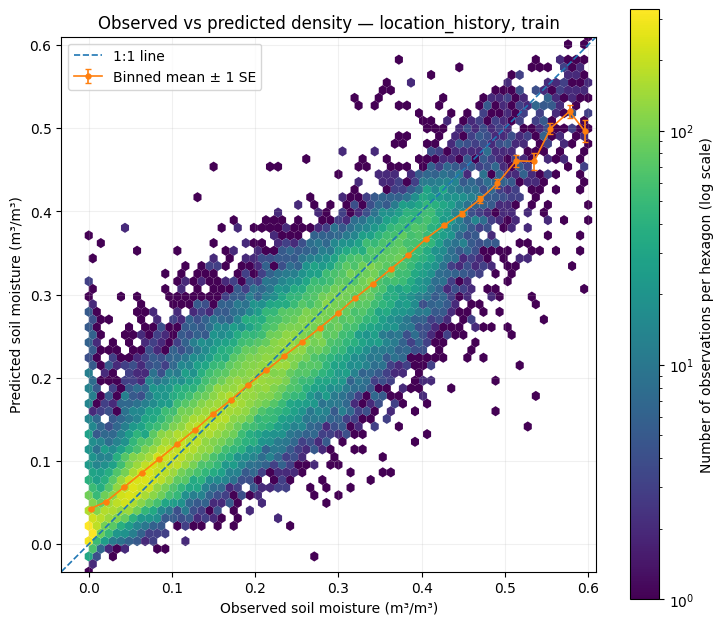

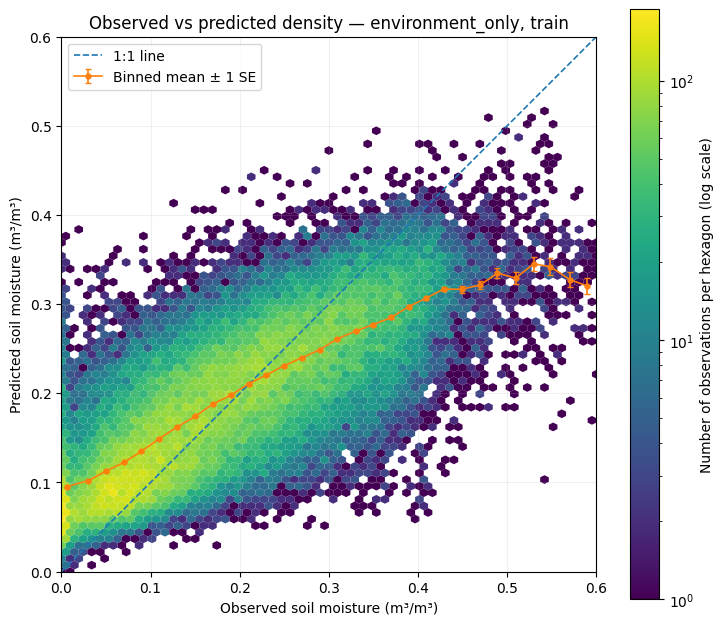

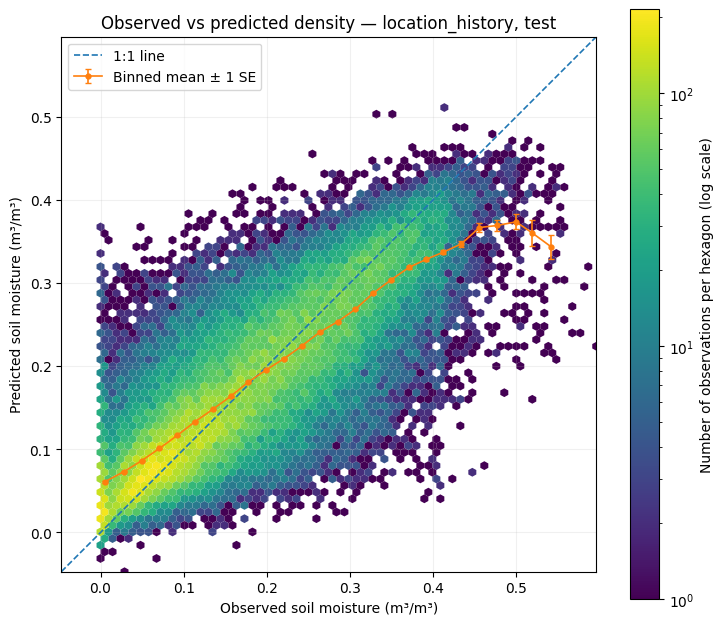

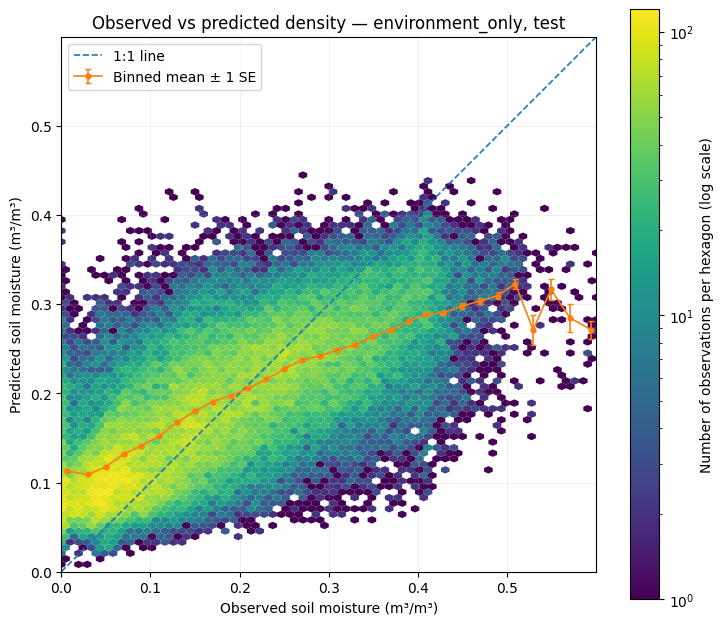

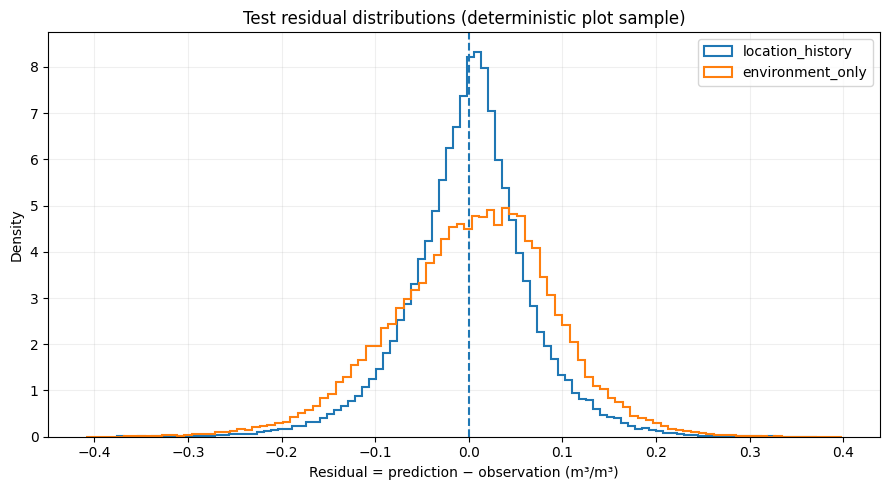

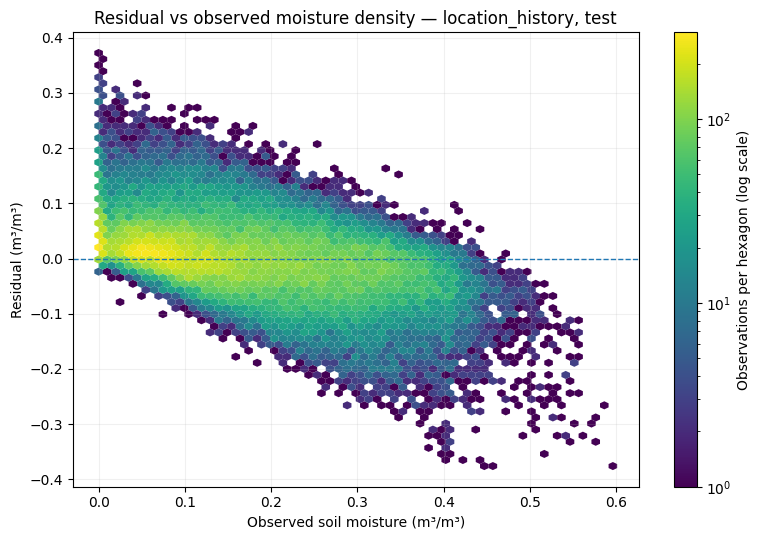

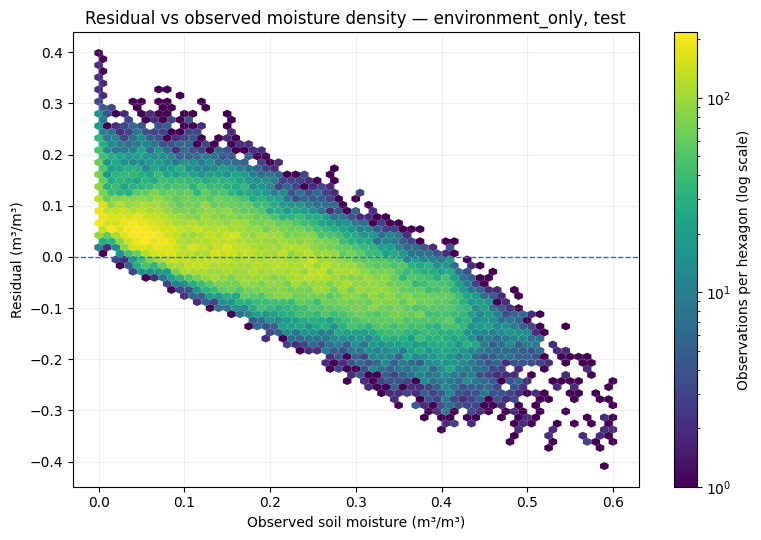

How much of each split is exactly zero / near-zero observed moisture, and what did the model predict?


,task_mode,split,observed_regime,n,pct_of_split,mean_observed,mean_predicted,median_predicted,bias_m3_m3,mae_m3_m3,rmse_m3_m3
0,location_history,train,positive_ge_0.02,2093850,94.45440,0.20164,0.19868,0.18834,-0.00297,0.03519,0.04739
1,location_history,train,near_zero_0_to_0.02,77396,3.49136,0.00944,0.04520,0.03425,0.03575,0.03681,0.05541
2,location_history,train,exact_zero,45538,2.05424,0.00000,0.04378,0.02306,0.04378,0.04492,0.07337
3,location_history,test,positive_ge_0.02,855454,94.49941,0.18747,0.18552,0.17436,-0.00195,0.04807,0.06513
4,location_history,test,exact_zero,18925,2.09059,0.00000,0.05992,0.04194,0.05992,0.06079,0.08601
5,location_history,test,near_zero_0_to_0.02,30869,3.41000,0.00972,0.06301,0.04921,0.05329,0.05400,0.07365
6,environment_only,train,positive_ge_0.02,2401976,94.41589,0.19753,0.19741,0.19545,-0.00011,0.05703,0.07357
7,environment_only,train,near_zero_0_to_0.02,88529,3.47986,0.00925,0.09402,0.08216,0.08476,0.08477,0.09799
8,environment_only,train,exact_zero,53533,2.10425,0.00000,0.10092,0.08025,0.10092,0.10092,0.11958
9,environment_only,test,positive_ge_0.02,610391,94.67595,0.19725,0.19556,0.19327,-0.00168,0.06581,0.08397


In [7]:
# 7. Pull a bounded plotting sample and inspect observed-vs-predicted values

# The full-table metrics are computed elsewhere from Parquet. This deterministic sample
# is only for legible visual diagnostics; it does not affect any reported metric.
def fetch_plot_sample(view, n=PLOT_SAMPLE_PER_SPLIT):
    return DB.execute(f"""
      SELECT sample_id, network, station_id, CAST(sample_date AS DATE) AS sample_date,
             latitude, longitude, y_true_m3_m3,
             prediction_m3_m3, raw_prediction_m3_m3,
             residual_m3_m3, absolute_error_m3_m3,
             anchor_smap_m3_m3
      FROM {view}
      WHERE isfinite(y_true_m3_m3) AND isfinite(prediction_m3_m3)
      ORDER BY hash(CAST(sample_id AS VARCHAR))
      LIMIT {int(n)}
    """).df()

PLOT_SAMPLES = {}
for split in ("train", "test"):
    for mode in ("location_history", "environment_only"):
        df = fetch_plot_sample(VIEWS[(mode, split)])
        PLOT_SAMPLES[(mode, split)] = df
        print(mode, split, "plot sample:", f"{len(df):,}")

# Hexbin shows point density without the overplotting in a conventional scatter plot.
# The overlaid binned mean makes systematic under-/overprediction easier to see.
for split in ("train", "test"):
    for mode in ("location_history", "environment_only"):
        df = PLOT_SAMPLES[(mode, split)].dropna(subset=["y_true_m3_m3", "prediction_m3_m3"])
        if df.empty:
            print(f"No finite prediction rows for {mode}/{split}; skipping plots.")
            continue
        x = df.y_true_m3_m3.to_numpy(dtype=float)
        y = df.prediction_m3_m3.to_numpy(dtype=float)
        lo = float(np.nanmin([np.nanmin(x), np.nanmin(y)]))
        hi = float(np.nanmax([np.nanmax(x), np.nanmax(y)]))
        if not np.isfinite(lo) or not np.isfinite(hi) or hi <= lo:
            print(f"Degenerate plot range for {mode}/{split}; skipping.")
            continue

        fig, ax = plt.subplots(figsize=(7.5, 6.5))
        hb = ax.hexbin(x, y, gridsize=62, mincnt=1, bins="log", linewidths=0)
        cb = fig.colorbar(hb, ax=ax)
        cb.set_label("Number of observations per hexagon (log scale)")
        ax.plot([lo, hi], [lo, hi], linestyle="--", linewidth=1.2, label="1:1 line")

        edges = np.linspace(lo, hi, 31)
        binned = pd.DataFrame({"observed": x, "predicted": y})
        binned["obs_bin"] = pd.cut(binned.observed, bins=edges, include_lowest=True, duplicates="drop")
        trend = (binned.groupby("obs_bin", observed=True)
                 .agg(x_mean=("observed", "mean"), y_mean=("predicted", "mean"),
                      y_sd=("predicted", "std"), n=("predicted", "size"))
                 .reset_index(drop=True))
        trend = trend[trend.n >= 10].copy()
        if not trend.empty:
            trend["y_se"] = trend.y_sd.fillna(0) / np.sqrt(trend.n)
            ax.errorbar(trend.x_mean, trend.y_mean, yerr=trend.y_se,
                        fmt="o-", markersize=3.5, linewidth=1.2, capsize=2,
                        label="Binned mean ± 1 SE")
        ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)
        ax.set_aspect("equal", adjustable="box")
        ax.set_xlabel("Observed soil moisture (m³/m³)")
        ax.set_ylabel("Predicted soil moisture (m³/m³)")
        ax.set_title(f"Observed vs predicted density — {mode}, {split}")
        ax.legend(); ax.grid(alpha=0.18); fig.tight_layout()
        fig.savefig(PLOTS_DIR / f"observed_vs_predicted_density_{mode}_{split}.png", dpi=180)
        plt.show(); plt.close(fig)

# Residual distributions and residual-vs-target density diagnostics.
fig, ax = plt.subplots(figsize=(9, 5))
for mode in ("location_history", "environment_only"):
    df = PLOT_SAMPLES[(mode, "test")]
    ax.hist(df.residual_m3_m3.dropna(), bins=100, density=True,
            histtype="step", linewidth=1.5, label=mode)
ax.axvline(0, linestyle="--")
ax.set_xlabel("Residual = prediction − observation (m³/m³)")
ax.set_ylabel("Density")
ax.set_title("Test residual distributions (deterministic plot sample)")
ax.legend(); ax.grid(alpha=0.2); fig.tight_layout()
fig.savefig(PLOTS_DIR / "test_residual_distributions.png", dpi=170); plt.show(); plt.close(fig)

for mode in ("location_history", "environment_only"):
    df = PLOT_SAMPLES[(mode, "test")].dropna(subset=["y_true_m3_m3", "residual_m3_m3"])
    if df.empty:
        continue
    fig, ax = plt.subplots(figsize=(8, 5.5))
    hb = ax.hexbin(df.y_true_m3_m3, df.residual_m3_m3,
                   gridsize=60, mincnt=1, bins="log", linewidths=0)
    fig.colorbar(hb, ax=ax, label="Observations per hexagon (log scale)")
    ax.axhline(0, linestyle="--", linewidth=1)
    ax.set_xlabel("Observed soil moisture (m³/m³)")
    ax.set_ylabel("Residual (m³/m³)")
    ax.set_title(f"Residual vs observed moisture density — {mode}, test")
    ax.grid(alpha=0.18); fig.tight_layout()
    fig.savefig(PLOTS_DIR / f"residual_vs_target_density_{mode}_test.png", dpi=180)
    plt.show(); plt.close(fig)

# A vertical pile-up at observed=0 can dominate a density plot. Quantify how often it
# occurs and whether the model predicts positive moisture for those nominally dry rows.
zero_regime_parts = []
for mode in ("location_history", "environment_only"):
    for split in ("train", "test"):
        view = VIEWS[(mode, split)]
        part = DB.execute(f"""
          SELECT '{mode}' AS task_mode, '{split}' AS split,
                 CASE WHEN y_true_m3_m3 <= 1e-6 THEN 'exact_zero'
                      WHEN y_true_m3_m3 < 0.02 THEN 'near_zero_0_to_0.02'
                      ELSE 'positive_ge_0.02' END AS observed_regime,
                 COUNT(*)::BIGINT AS n,
                 100.0 * COUNT(*) / SUM(COUNT(*)) OVER () AS pct_of_split,
                 AVG(y_true_m3_m3) AS mean_observed,
                 AVG(prediction_m3_m3) AS mean_predicted,
                 MEDIAN(prediction_m3_m3) AS median_predicted,
                 AVG(residual_m3_m3) AS bias_m3_m3,
                 AVG(absolute_error_m3_m3) AS mae_m3_m3,
                 SQRT(AVG(squared_error_m3_m6)) AS rmse_m3_m3
          FROM {view}
          WHERE isfinite(y_true_m3_m3) AND isfinite(prediction_m3_m3)
            AND isfinite(residual_m3_m3)
          GROUP BY CASE WHEN y_true_m3_m3 <= 1e-6 THEN 'exact_zero'
                        WHEN y_true_m3_m3 < 0.02 THEN 'near_zero_0_to_0.02'
                        ELSE 'positive_ge_0.02' END
        """).df()
        zero_regime_parts.append(part)
ZERO_REGIME_METRICS = pd.concat(zero_regime_parts, ignore_index=True)
ZERO_REGIME_METRICS.to_csv(TABLES_DIR / "zero_and_dry_target_diagnostics.csv", index=False)
print("How much of each split is exactly zero / near-zero observed moisture, and what did the model predict?")
display(ZERO_REGIME_METRICS.round(5))


## 5) Station-level and network-level error patterns

Station metrics use every prediction for that station. Small stations can have unstable metrics, so the default table/plots filter to stations with at least `MIN_STATION_ROWS` observations. The full unfiltered summary is still saved as CSV.

,network,station_id,n,latitude,longitude,bias_m3_m3,mae_m3_m3,rmse_m3_m3,r2
2578,SNOTEL,SNOTEL__MF_Nooksack,191,48.82441,-121.92947,0.25124,0.25124,0.26078,NaN
2823,FMI,FMI__SOD021,58,67.36691,26.65176,-0.21528,0.21528,0.22969,-10.52379
2746,USCRN,USCRN__Coos_Bay_8_SW,422,43.27180,-124.31860,-0.19146,0.19590,0.22508,-3.40769
3049,FMI,FMI__SOD101,556,67.35919,26.68595,-0.19215,0.19250,0.20625,-6.11293
2472,SCAN,SCAN__Guilarte_Forest,621,18.14638,-66.76718,-0.17737,0.17949,0.19889,-3.12894
2309,SNOTEL,SNOTEL__Kelly_Station,258,67.92970,-162.29060,-0.11632,0.16211,0.19345,-0.73079
2540,SNOTEL,SNOTEL__Poison_Flat,546,38.50576,-119.62624,-0.15031,0.15433,0.18028,-1.28990
2469,SNOTEL,SNOTEL__Sheep_Mtn.,813,43.21030,-111.68792,0.10879,0.14728,0.17425,-0.74236
2354,SNOTEL,SNOTEL__Two_Ocean_Plateau,247,44.15178,-110.22122,-0.15171,0.15476,0.16985,-4.36029
2863,SNOTEL,SNOTEL__Middle_Fork_Camp,96,39.79565,-106.02802,-0.12212,0.14944,0.16734,-1.08231


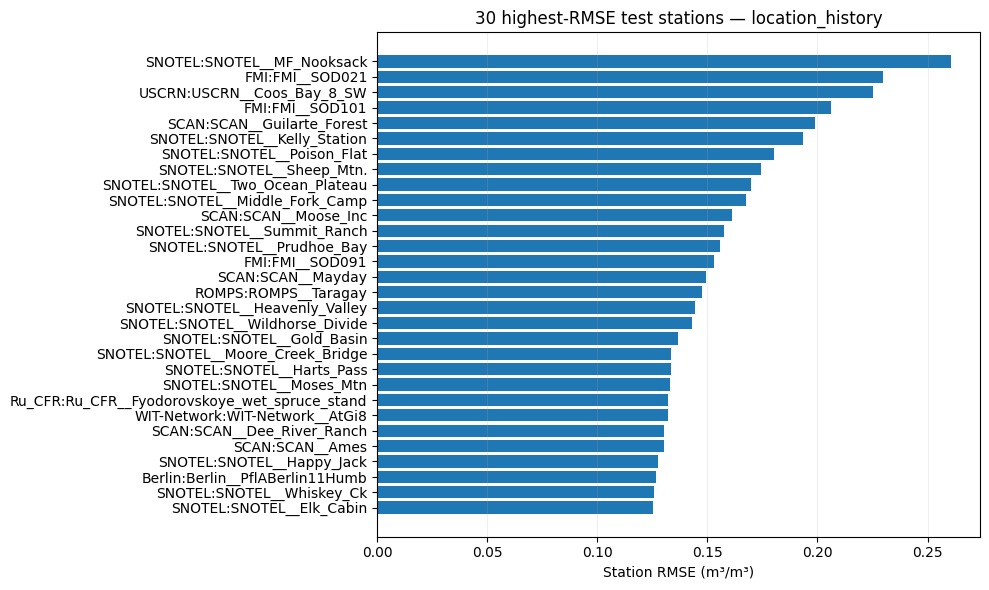

,network,station_id,n,latitude,longitude,bias_m3_m3,mae_m3_m3,rmse_m3_m3,r2
5094,BIEBRZA_S-1,BIEBRZA_S-1__marshland_soil_25,24,53.62030,22.87915,-0.30866,0.30866,0.31070,-1121.14333
5157,TWENTE,TWENTE__ITCSM_06a,81,52.41389,6.63667,-0.30028,0.30028,0.30447,-20.42972
5089,BIEBRZA_S-1,BIEBRZA_S-1__marshland_soil_28,41,53.62178,22.87884,-0.28903,0.28903,0.29627,-61.51851
4983,BIEBRZA_S-1,BIEBRZA_S-1__marshland_soil_23,64,53.61899,22.88195,-0.26665,0.26665,0.27451,-47.71373
5239,MySMNet,MySMNet__MPOB-BL1,275,1.91700,103.44800,0.27195,0.27195,0.27396,-56.43399
4994,FMI,FMI__SOD092,218,67.37074,26.63978,-0.25789,0.25789,0.26216,-33.27232
5323,BIEBRZA_S-1,BIEBRZA_S-1__marshland_soil_15,337,53.60578,22.87850,-0.20791,0.20840,0.22285,-11.53509
5168,COSMOS,COSMOS__Howland,572,45.20410,-68.74020,-0.21193,0.21193,0.21811,-12.81090
5103,SNOTEL,SNOTEL__Elwood_Pass,168,37.40563,-106.64136,-0.20698,0.20698,0.21270,-10.08906
5194,MySMNet,MySMNet__MARDI-L2,275,1.97400,103.35800,0.20682,0.20682,0.21126,-13.31565


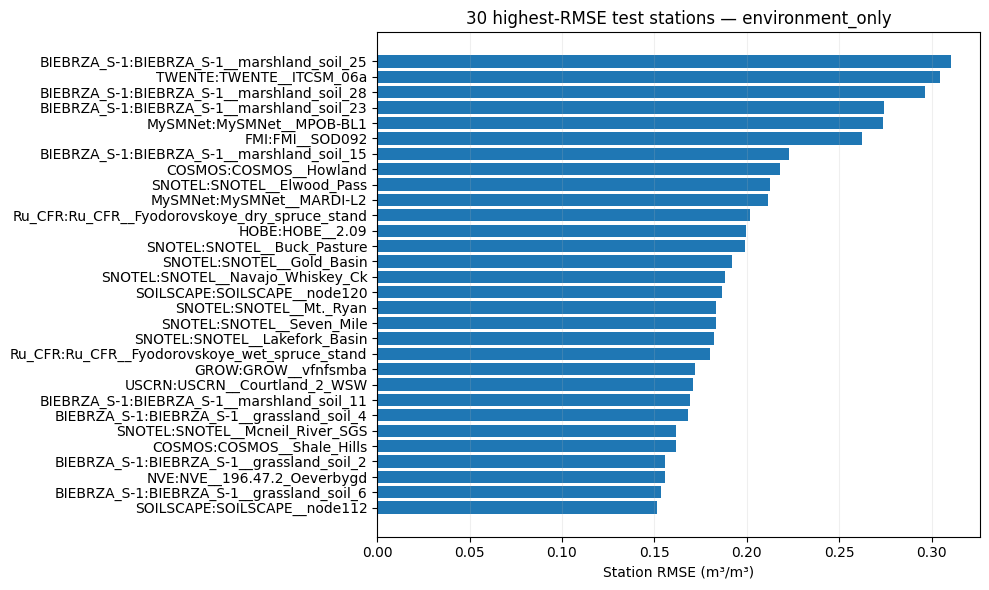

,task_mode,split,network,n,n_stations,bias_m3_m3,mae_m3_m3,rmse_m3_m3,pearson_r
147,environment_only,test,MySMNet,1042,4,0.18330,0.18330,0.19990,0.16313
185,environment_only,test,Ru_CFR,1487,2,-0.17223,0.18186,0.19806,0.08630
186,environment_only,test,BIEBRZA_S-1,3956,10,-0.15048,0.15059,0.17110,0.56065
177,environment_only,test,IPE,1027,1,0.13759,0.13759,0.14773,0.68517
165,environment_only,test,TWENTE,8518,7,-0.09256,0.10036,0.12476,0.71934
...,...,...,...,...,...,...,...,...,...
77,location_history,test,REMEDHUS,12741,18,-0.00765,0.02832,0.03981,0.91074
146,environment_only,test,IMA_CAN1,247,1,-0.00787,0.03043,0.03865,0.66069
149,environment_only,test,CTP_SMTMN,503,12,0.00593,0.03033,0.03574,0.35692
67,location_history,test,FR_Aqui,1623,3,0.00389,0.02659,0.03532,0.72759


In [8]:
# 8. Complete per-station metrics for each model and split
station_frames = []
for (mode, split), view in VIEWS.items():
    part = DB.execute(f"""
      SELECT '{mode}' AS task_mode, '{split}' AS split,
             network, station_id, station_key,
             AVG(latitude) AS latitude, AVG(longitude) AS longitude,
             COUNT(*)::BIGINT AS n,
             AVG(residual_m3_m3) AS bias_m3_m3,
             AVG(absolute_error_m3_m3) AS mae_m3_m3,
             SQRT(AVG(squared_error_m3_m6)) AS rmse_m3_m3,
             CASE WHEN (SUM(y_true_m3_m3*y_true_m3_m3)
                        - SUM(y_true_m3_m3)*SUM(y_true_m3_m3)/COUNT(*)) > 0
                  THEN 1.0 - SUM(squared_error_m3_m6) /
                       (SUM(y_true_m3_m3*y_true_m3_m3)
                        - SUM(y_true_m3_m3)*SUM(y_true_m3_m3)/COUNT(*))
                  ELSE NULL END AS r2,
             CORR(y_true_m3_m3, prediction_m3_m3) AS pearson_r
      FROM {view}
      GROUP BY network, station_id, station_key
    """).df()
    station_frames.append(part)
STATION_METRICS = pd.concat(station_frames, ignore_index=True)
STATION_METRICS.to_csv(TABLES_DIR / "station_metrics_all.csv", index=False)

STATION_TEST = STATION_METRICS[(STATION_METRICS.split == "test") & (STATION_METRICS.n >= MIN_STATION_ROWS)].copy()
for mode in ("location_history", "environment_only"):
    worst = STATION_TEST[STATION_TEST.task_mode == mode].nlargest(30, "rmse_m3_m3")
    worst.to_csv(TABLES_DIR / f"worst_30_stations_{mode}_test.csv", index=False)
    display(worst[["network", "station_id", "n", "latitude", "longitude", "bias_m3_m3", "mae_m3_m3", "rmse_m3_m3", "r2"]].head(15).round(5))
    fig, ax = plt.subplots(figsize=(10, 6))
    plot_worst = worst.sort_values("rmse_m3_m3", ascending=True)
    labels = (plot_worst.network.astype(str) + ":" + plot_worst.station_id.astype(str)).tolist()
    ax.barh(labels, plot_worst.rmse_m3_m3)
    ax.set_xlabel("Station RMSE (m³/m³)")
    ax.set_title(f"30 highest-RMSE test stations — {mode}")
    ax.grid(axis="x", alpha=0.2); fig.tight_layout()
    fig.savefig(PLOTS_DIR / f"worst_30_stations_{mode}_test.png", dpi=160)
    plt.show(); plt.close(fig)

# Network summaries expose whether a few networks dominate the error.
network_frames = []
for (mode, split), view in VIEWS.items():
    part = DB.execute(f"""
      SELECT '{mode}' AS task_mode, '{split}' AS split, network,
             COUNT(*)::BIGINT AS n,
             COUNT(DISTINCT station_key) AS n_stations,
             AVG(residual_m3_m3) AS bias_m3_m3,
             AVG(absolute_error_m3_m3) AS mae_m3_m3,
             SQRT(AVG(squared_error_m3_m6)) AS rmse_m3_m3,
             CORR(y_true_m3_m3, prediction_m3_m3) AS pearson_r
      FROM {view} GROUP BY network
    """).df()
    network_frames.append(part)
NETWORK_METRICS = pd.concat(network_frames, ignore_index=True)
NETWORK_METRICS.to_csv(TABLES_DIR / "network_metrics.csv", index=False)
display(NETWORK_METRICS[NETWORK_METRICS.split == "test"].sort_values("rmse_m3_m3", ascending=False).round(5))

## 6) Direct station-by-station model comparison

This isolates where location history helps or hurts, using only matched test observations and identical target values. `location_minus_environment_rmse < 0` means location history lowers station RMSE. The win-rate is the percentage of matched observations where the absolute error from `location_history` is smaller.

Stations where location_history lowers RMSE the most (test):


,split,network,station_id,n,location_mae,location_rmse,environment_mae,environment_rmse,location_minus_environment_mae,location_minus_environment_rmse,location_win_pct
1802,test,SNOTEL,SNOTEL__Mt._Ryan,585,0.08822,0.10166,0.20136,0.20549,-0.11314,-0.10383,100.00000
1717,test,Ru_CFR,Ru_CFR__Fyodorovskoye_dry_spruce_stand,419,0.09403,0.12050,0.21920,0.22350,-0.12517,-0.10300,93.07876
1809,test,REMEDHUS,REMEDHUS__El_Coto,574,0.03245,0.03624,0.12994,0.13752,-0.09750,-0.10128,99.82578
1761,test,RSMN,RSMN__Darabani,333,0.02660,0.03465,0.10865,0.12919,-0.08205,-0.09454,92.19219
1784,test,SNOTEL,SNOTEL__Navajo_Whiskey_Ck,1151,0.06855,0.08730,0.16774,0.18020,-0.09919,-0.09290,82.62381
1695,test,USCRN,USCRN__Watkinsville_5_SSE,1051,0.04271,0.05194,0.13965,0.14362,-0.09694,-0.09168,99.52426
1835,test,SNOTEL,SNOTEL__Buck_Pasture,727,0.07838,0.11102,0.19041,0.19886,-0.11203,-0.08785,81.98074
1681,test,USCRN,USCRN__John_Day_35_WNW,1201,0.03053,0.03889,0.11040,0.12231,-0.07987,-0.08342,97.91840
1783,test,SNOTEL,SNOTEL__Atlanta_Summit,596,0.05768,0.07472,0.14172,0.15516,-0.08405,-0.08044,94.63087
1704,test,SCAN,SCAN__Watkinsville_#1,1365,0.03799,0.04994,0.11828,0.12498,-0.08029,-0.07504,90.10989


Stations where environment_only lowers RMSE the most (test):


,split,network,station_id,n,location_mae,location_rmse,environment_mae,environment_rmse,location_minus_environment_mae,location_minus_environment_rmse,location_win_pct
1850,test,SCAN,SCAN__Johnson_Farm,1208,0.09126,0.10466,0.04728,0.05694,0.04399,0.04772,15.97682
1772,test,SNOTEL,SNOTEL__Middle_Fork_Camp,96,0.14944,0.16734,0.11137,0.13162,0.03806,0.03572,20.83333
1708,test,SNOTEL,SNOTEL__Elk_Cabin,1096,0.10122,0.12524,0.07531,0.09214,0.02590,0.03309,31.66058
1870,test,Berlin,Berlin__PflABerlin11Humb,1282,0.11733,0.12659,0.08393,0.09394,0.03339,0.03265,9.20437
1842,test,USCRN,USCRN__Edinburg_17_NNE,1324,0.05720,0.06493,0.02868,0.03364,0.02853,0.03129,15.25680
1869,test,SNOTEL,SNOTEL__Two_Ocean_Plateau,247,0.15476,0.16985,0.13663,0.14528,0.01813,0.02457,38.05668
1798,test,SNOTEL,SNOTEL__Bear_Creek,952,0.05257,0.06303,0.03093,0.03907,0.02164,0.02396,30.56723
1722,test,SNOTEL,SNOTEL__Chemult_Alternate,282,0.06924,0.08186,0.04540,0.05793,0.02385,0.02393,26.59574
1741,test,XMS-CAT,XMS-CAT__Clarella,1316,0.07864,0.09801,0.06293,0.07494,0.01571,0.02308,34.87842
1707,test,RISMA,RISMA__MB24,646,0.04124,0.05292,0.02738,0.03428,0.01386,0.01865,33.59133


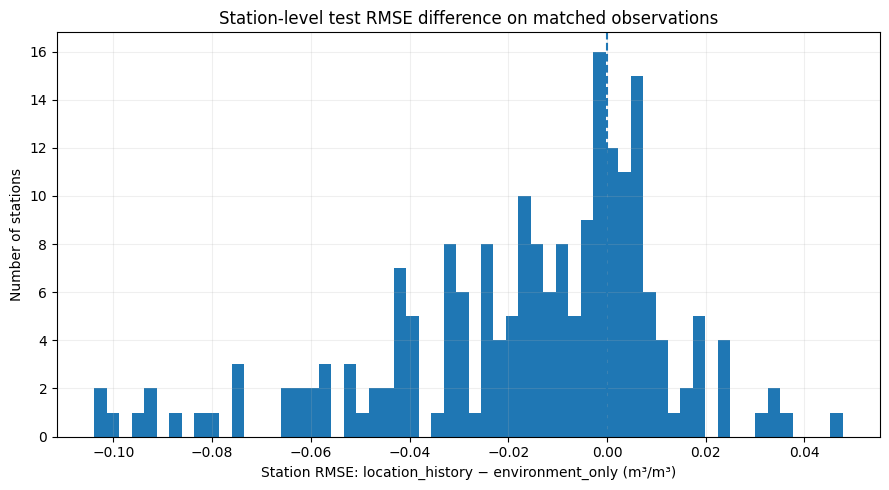

,network,n,location_mae,location_rmse,environment_mae,environment_rmse,location_minus_environment_mae,location_win_pct
15,Ru_CFR,517,0.09784,0.12283,0.20935,0.21727,-0.11151,89.36170
18,COSMOS-UK,5,0.03407,0.04078,0.10104,0.12006,-0.06696,100.00000
5,REMEDHUS,4212,0.02796,0.03602,0.06729,0.08041,-0.03933,79.39221
12,RSMN,1001,0.04632,0.05885,0.07762,0.09976,-0.03130,62.43756
2,USCRN,26083,0.03640,0.04843,0.06128,0.07559,-0.02488,69.68524
13,iRON,938,0.03654,0.04621,0.05703,0.07384,-0.02049,61.19403
16,ARM,480,0.03148,0.04012,0.05184,0.06240,-0.02037,69.79167
8,SMOSMANIA,3489,0.03761,0.04800,0.05724,0.07439,-0.01963,65.20493
7,Berlin,3768,0.06331,0.08236,0.08059,0.08973,-0.01727,58.41295
0,SNOTEL,74774,0.06162,0.08057,0.07836,0.09850,-0.01674,60.87276


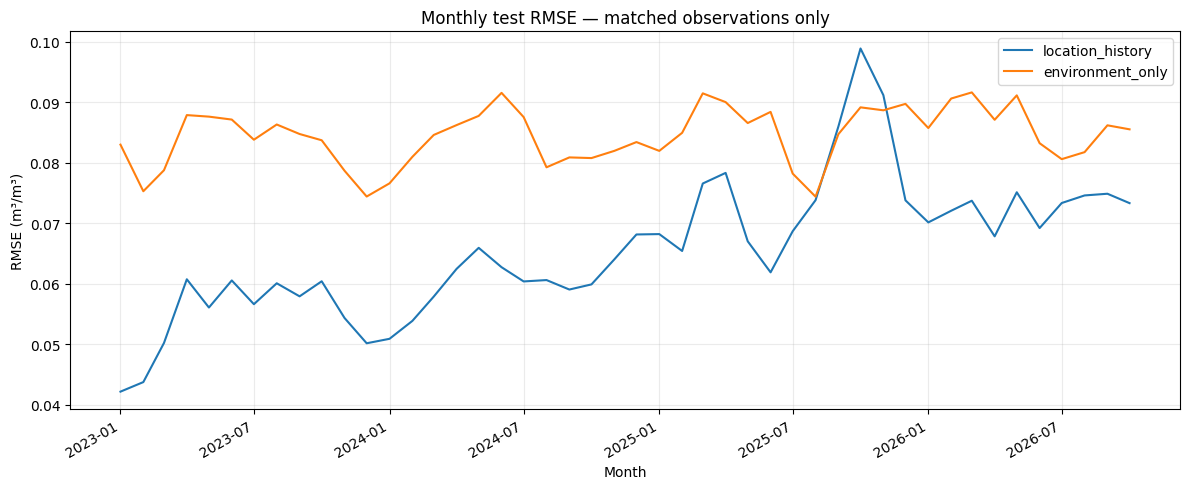

In [9]:
# 9. Per-station paired comparison on shared test samples
paired_station_parts = []
for split, pview in PAIR_VIEWS.items():
    part = DB.execute(f"""
      SELECT '{split}' AS split, network, station_id,
             COUNT(*)::BIGINT AS n,
             AVG(abs_error_location) AS location_mae,
             SQRT(AVG(POWER(residual_location, 2))) AS location_rmse,
             AVG(abs_error_environment) AS environment_mae,
             SQRT(AVG(POWER(residual_environment, 2))) AS environment_rmse,
             AVG(abs_error_location-abs_error_environment) AS location_minus_environment_mae,
             SQRT(AVG(POWER(residual_location,2))) - SQRT(AVG(POWER(residual_environment,2))) AS location_minus_environment_rmse,
             100.0*AVG(CASE WHEN abs_error_location < abs_error_environment THEN 1.0 ELSE 0.0 END) AS location_win_pct
      FROM {pview}
      WHERE ABS(y_location-y_environment) <= 1e-5
      GROUP BY network, station_id
    """).df()
    paired_station_parts.append(part)
PAIRED_STATION = pd.concat(paired_station_parts, ignore_index=True)
PAIRED_STATION.to_csv(TABLES_DIR / "paired_station_comparison.csv", index=False)
PAIRED_TEST_STATION = PAIRED_STATION[(PAIRED_STATION.split == "test") & (PAIRED_STATION.n >= MIN_STATION_ROWS)].copy()

print("Stations where location_history lowers RMSE the most (test):")
display(PAIRED_TEST_STATION.nsmallest(20, "location_minus_environment_rmse").round(5))
print("Stations where environment_only lowers RMSE the most (test):")
display(PAIRED_TEST_STATION.nlargest(20, "location_minus_environment_rmse").round(5))

fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(PAIRED_TEST_STATION.location_minus_environment_rmse.dropna(), bins=60)
ax.axvline(0, linestyle="--")
ax.set_xlabel("Station RMSE: location_history − environment_only (m³/m³)")
ax.set_ylabel("Number of stations")
ax.set_title("Station-level test RMSE difference on matched observations")
ax.grid(alpha=0.2); fig.tight_layout()
fig.savefig(PLOTS_DIR / "paired_station_rmse_difference_test.png", dpi=160)
plt.show(); plt.close(fig)

# Network-level paired comparison.
paired_network = DB.execute(f"""
  SELECT network, COUNT(*)::BIGINT AS n,
         AVG(abs_error_location) AS location_mae,
         SQRT(AVG(POWER(residual_location,2))) AS location_rmse,
         AVG(abs_error_environment) AS environment_mae,
         SQRT(AVG(POWER(residual_environment,2))) AS environment_rmse,
         AVG(abs_error_location-abs_error_environment) AS location_minus_environment_mae,
         100.0*AVG(CASE WHEN abs_error_location < abs_error_environment THEN 1.0 ELSE 0.0 END) AS location_win_pct
  FROM {PAIR_VIEWS['test']}
  WHERE ABS(y_location-y_environment) <= 1e-5
  GROUP BY network ORDER BY n DESC
""").df()
paired_network.to_csv(TABLES_DIR / "paired_network_comparison_test.csv", index=False)
display(paired_network.sort_values("location_minus_environment_mae").round(5))

# Monthly paired comparison: both models scored on the same test rows each month.
PAIRED_MONTHLY_TEST = DB.execute(f"""
  SELECT DATE_TRUNC('month', sample_date) AS month,
         COUNT(*)::BIGINT AS n,
         AVG(abs_error_location) AS location_mae,
         SQRT(AVG(POWER(residual_location,2))) AS location_rmse,
         AVG(abs_error_environment) AS environment_mae,
         SQRT(AVG(POWER(residual_environment,2))) AS environment_rmse,
         AVG(abs_error_location-abs_error_environment) AS location_minus_environment_mae,
         100.0*AVG(CASE WHEN abs_error_location < abs_error_environment THEN 1.0 ELSE 0.0 END) AS location_win_pct
  FROM {PAIR_VIEWS['test']}
  WHERE ABS(y_location-y_environment) <= 1e-5
  GROUP BY DATE_TRUNC('month', sample_date)
  ORDER BY DATE_TRUNC('month', sample_date)
""").df()
PAIRED_MONTHLY_TEST.to_csv(TABLES_DIR / "paired_monthly_comparison_test.csv", index=False)
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(pd.to_datetime(PAIRED_MONTHLY_TEST.month), PAIRED_MONTHLY_TEST.location_rmse, label="location_history")
ax.plot(pd.to_datetime(PAIRED_MONTHLY_TEST.month), PAIRED_MONTHLY_TEST.environment_rmse, label="environment_only")
ax.set_xlabel("Month"); ax.set_ylabel("RMSE (m³/m³)")
ax.set_title("Monthly test RMSE — matched observations only")
ax.legend(); ax.grid(alpha=0.25); fig.autofmt_xdate(); fig.tight_layout()
fig.savefig(PLOTS_DIR / "paired_monthly_test_rmse.png", dpi=160)
plt.show(); plt.close(fig)


## 7) Geographic error patterns

The export includes station latitude and longitude. The plots below are longitude/latitude scatter views, not political-boundary maps. A grid summary uses 2° cells by default, reducing station-level noise while preserving broad geographic structure.

Cartopy is not available; maps will be coordinate scatter plots without country borders.
For country borders, install Cartopy (for example: conda install -c conda-forge cartopy).


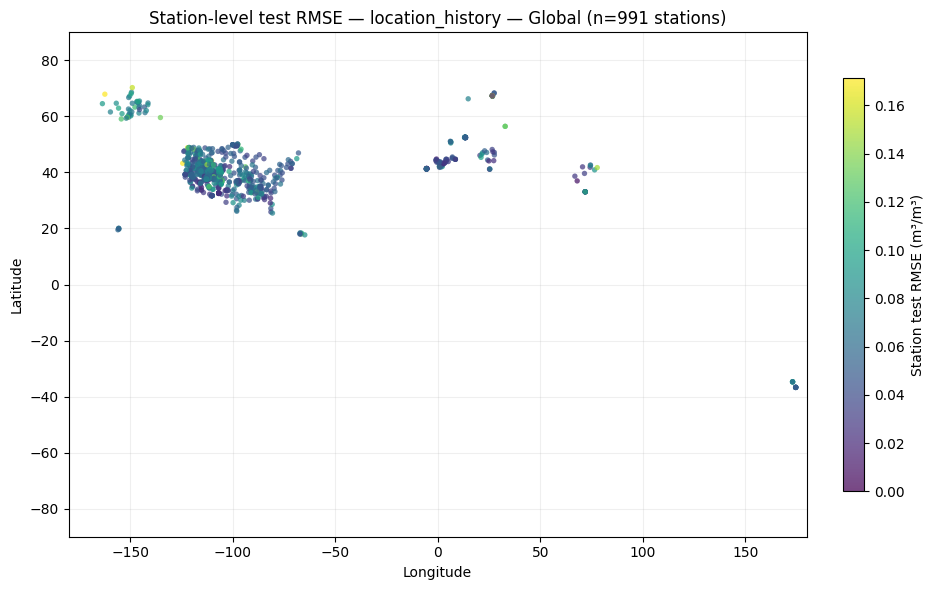

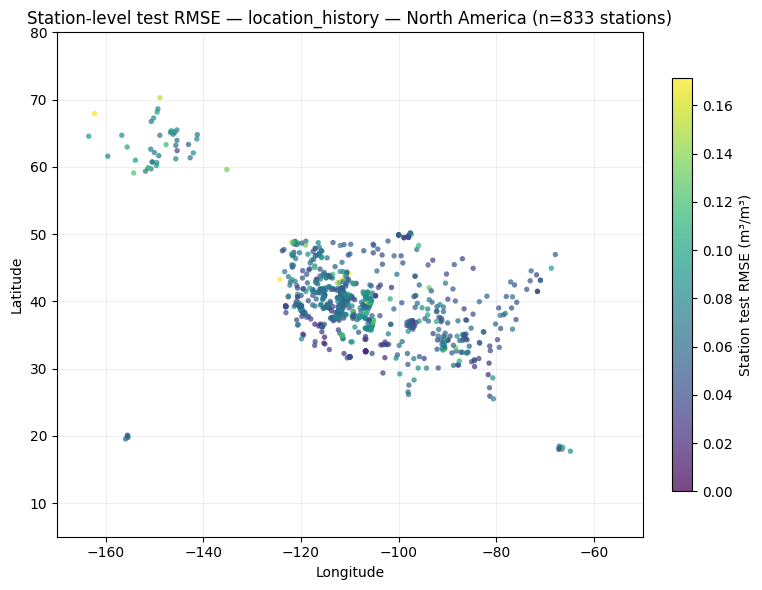

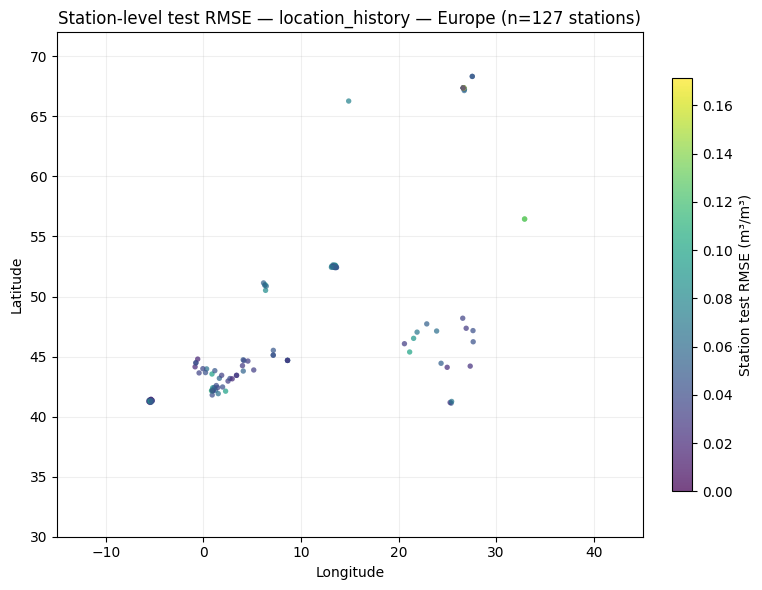

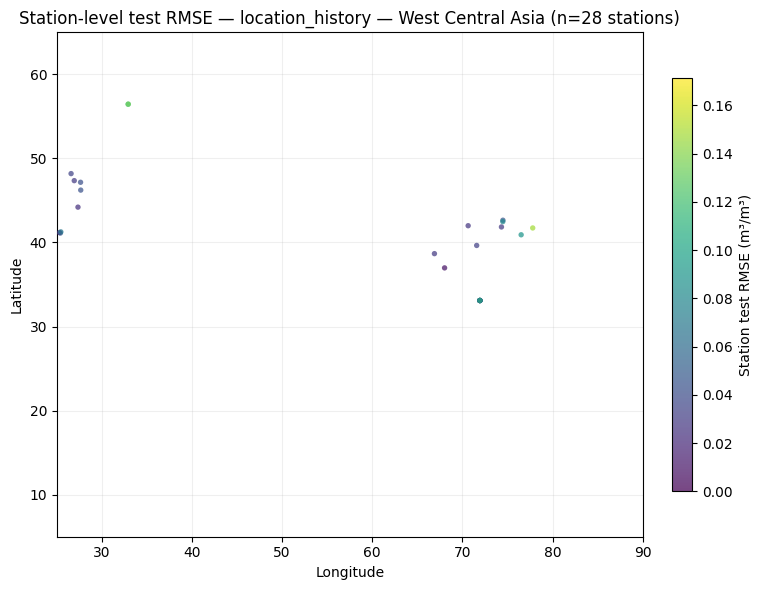

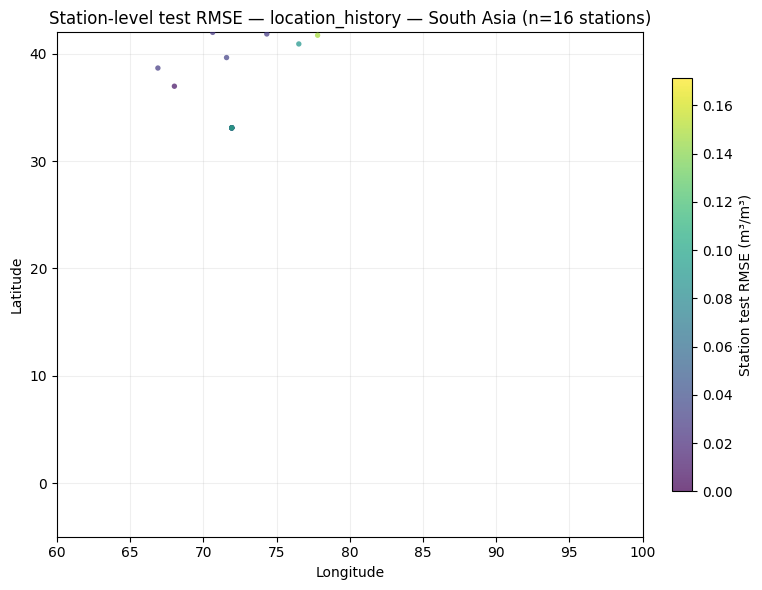

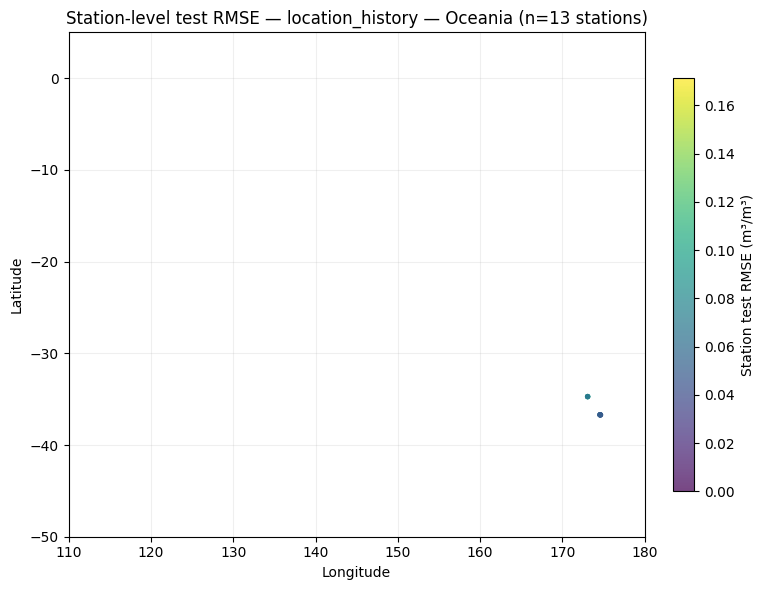

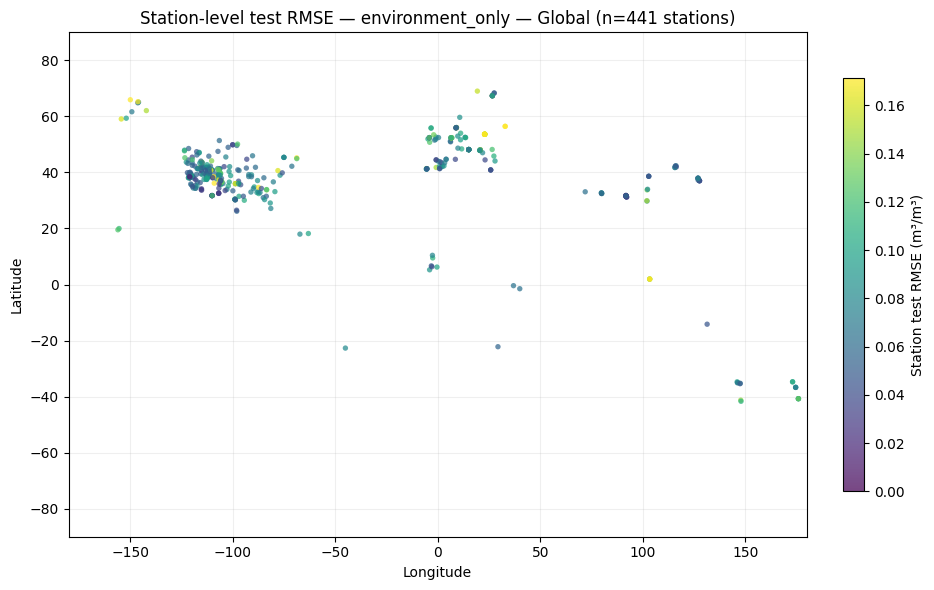

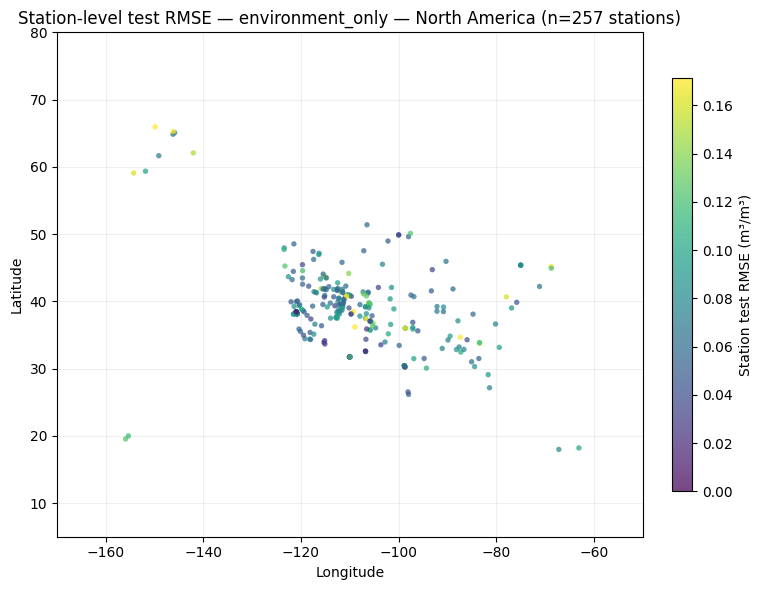

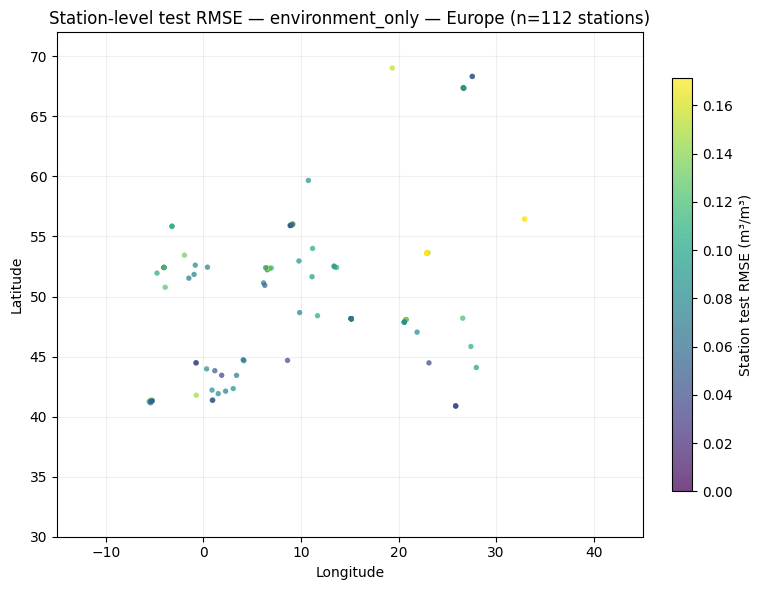

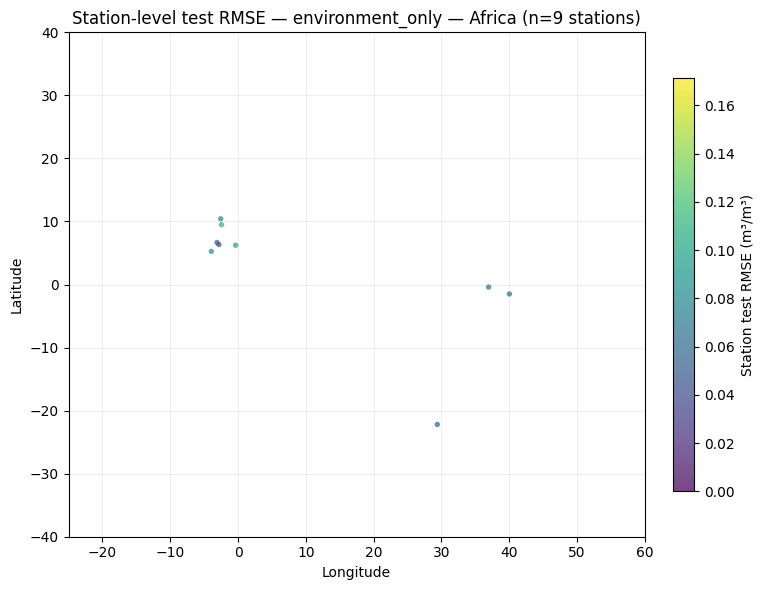

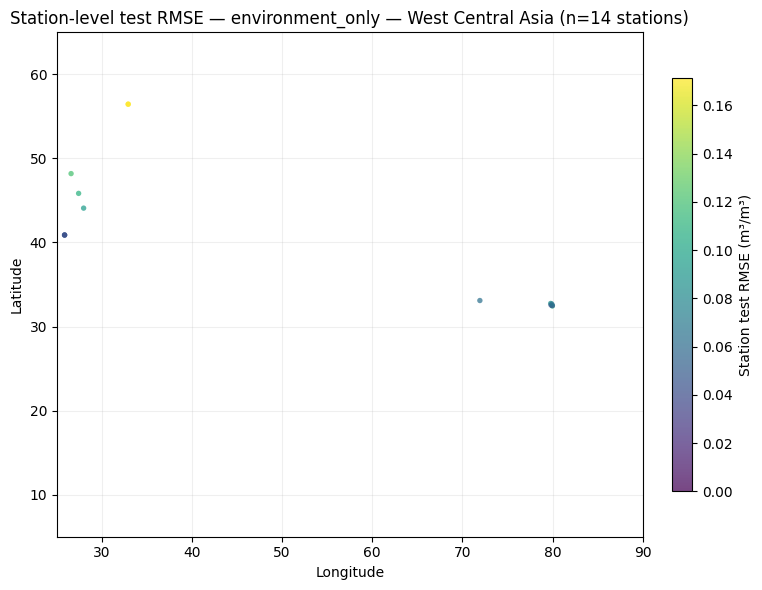

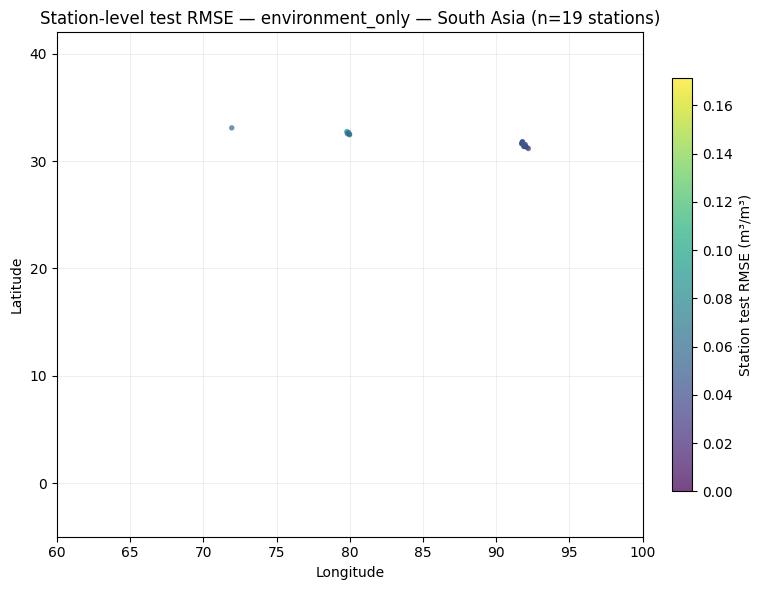

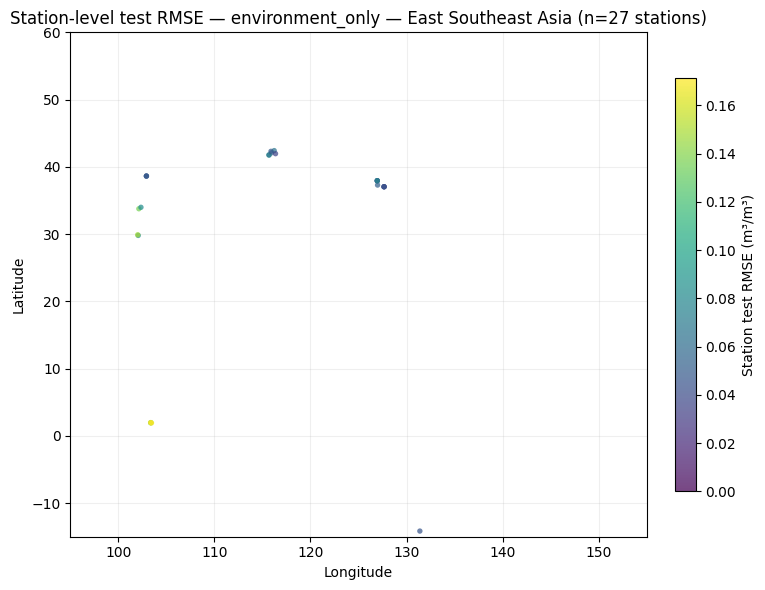

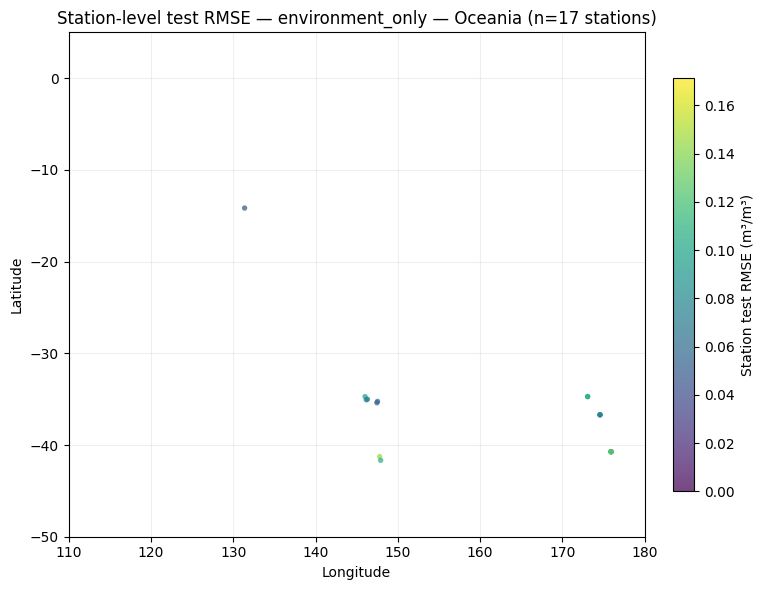

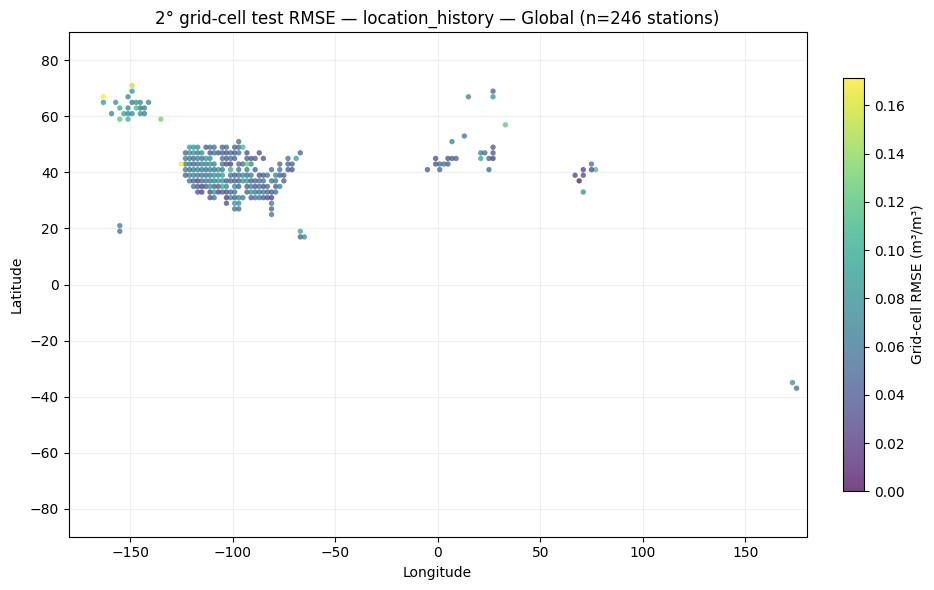

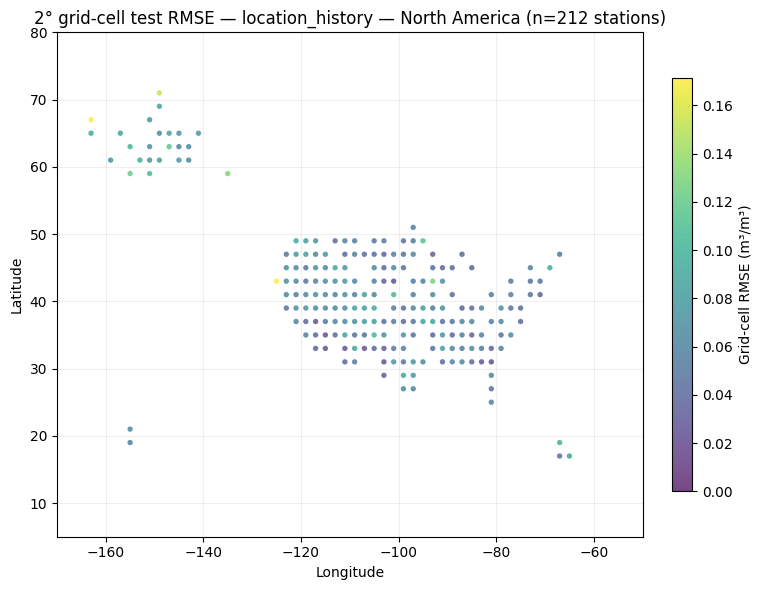

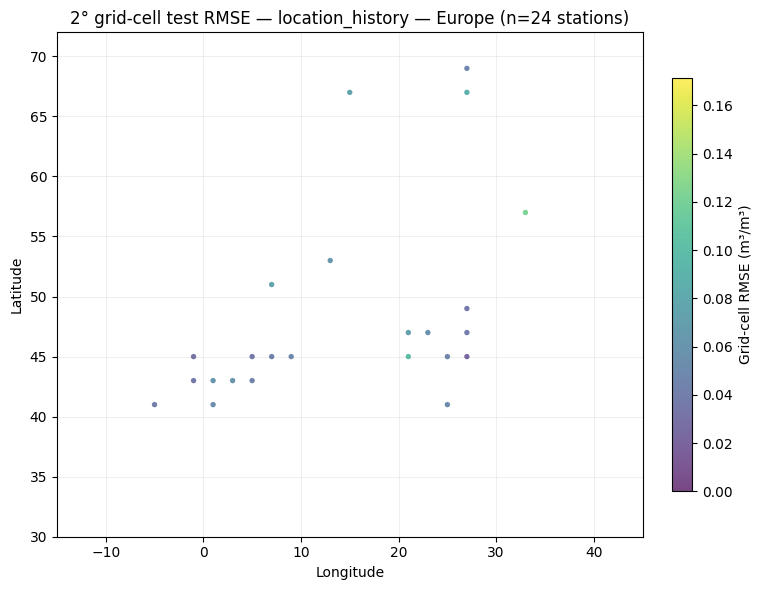

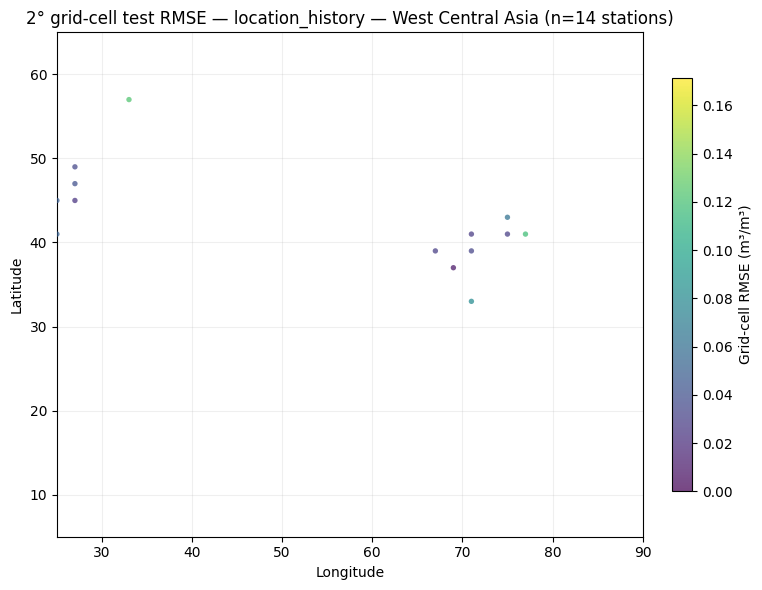

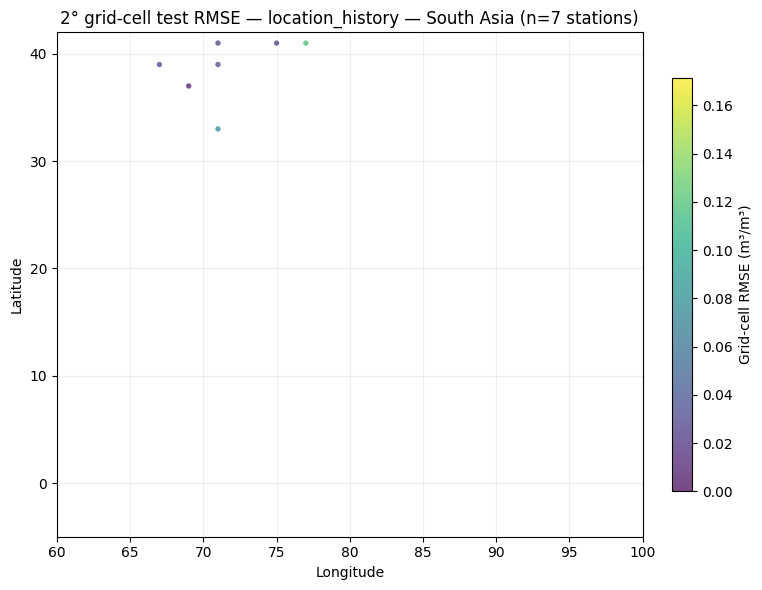

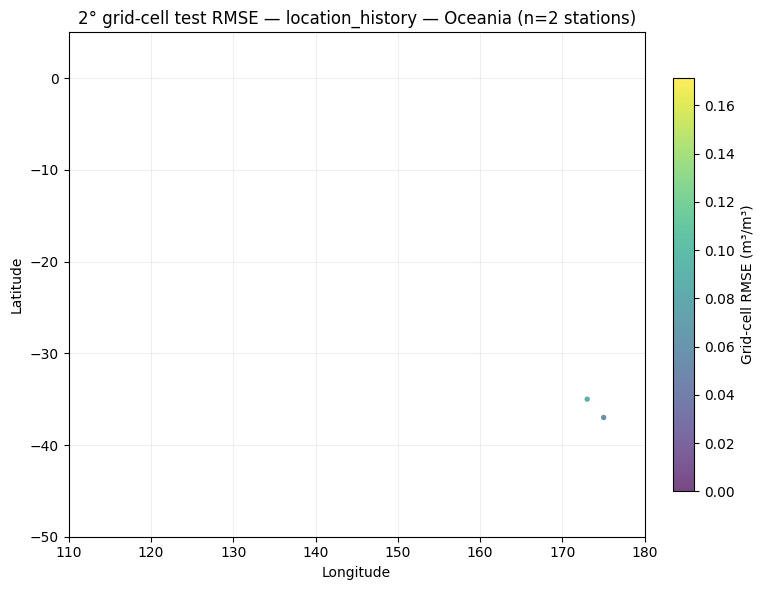

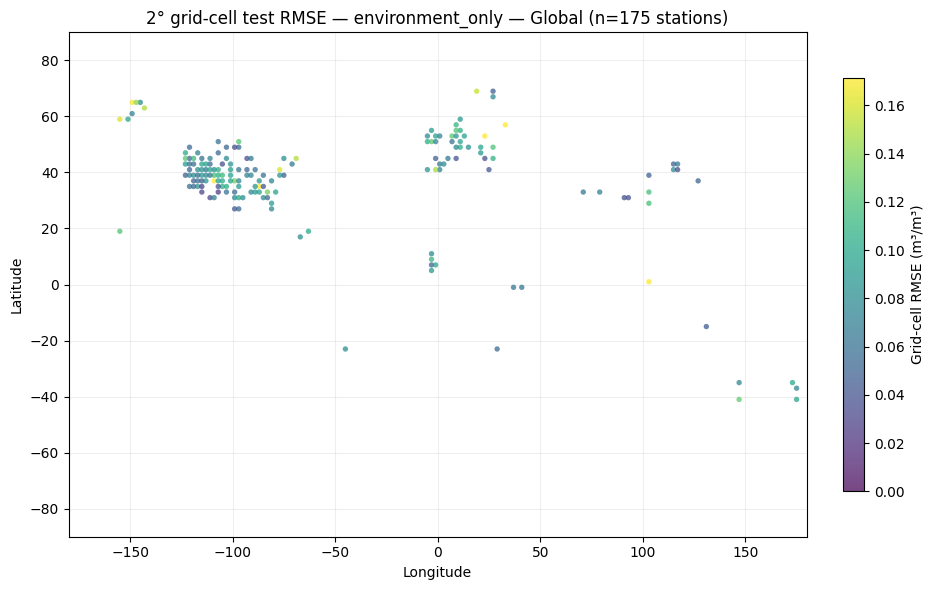

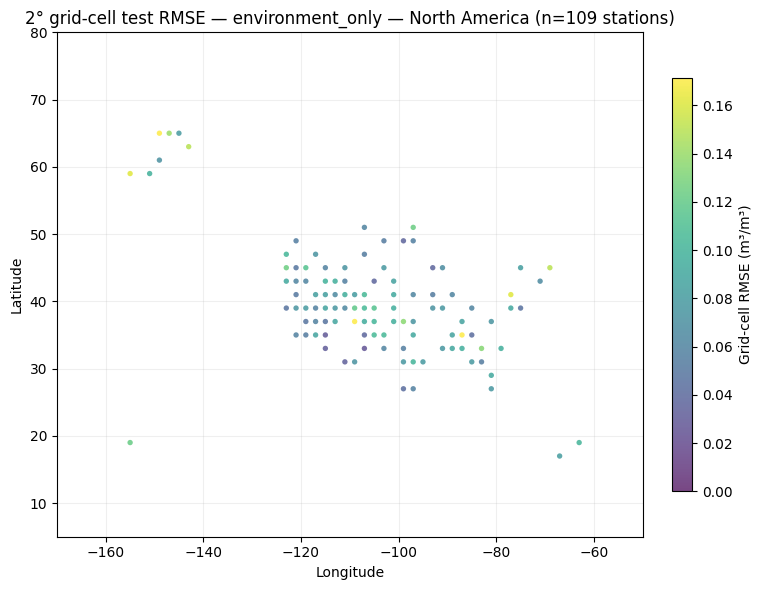

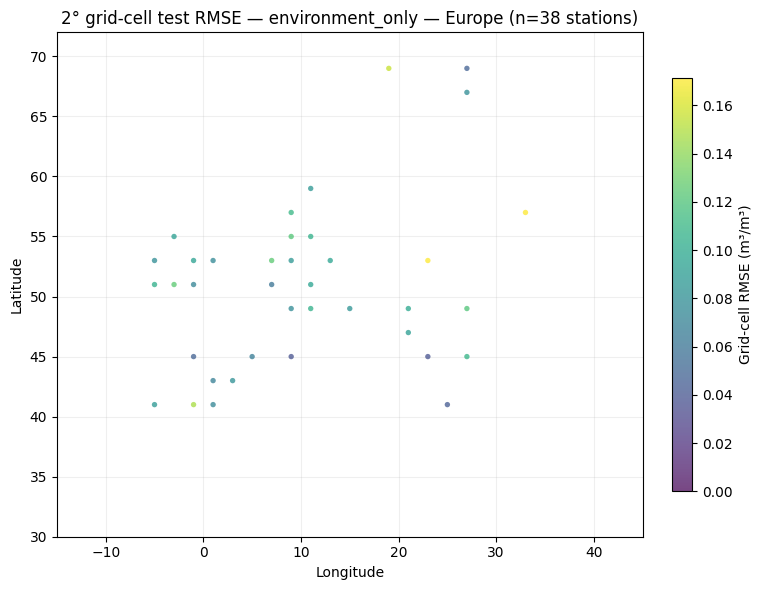

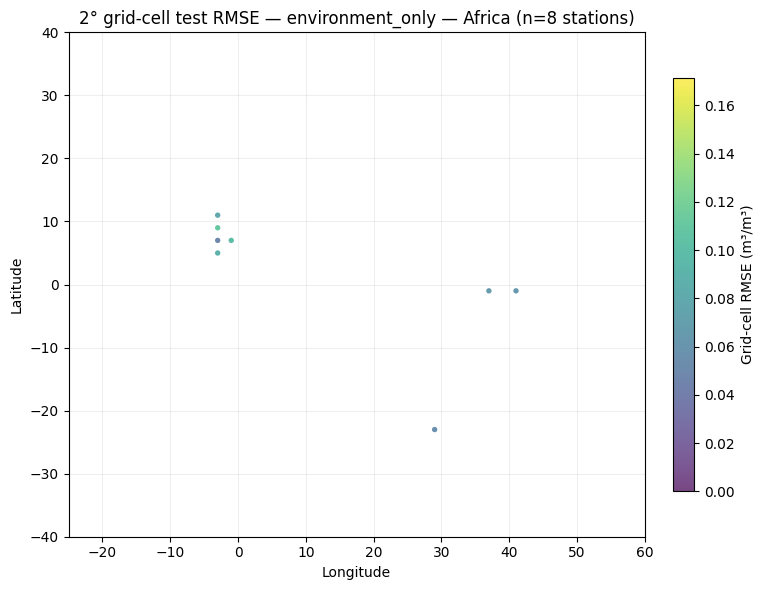

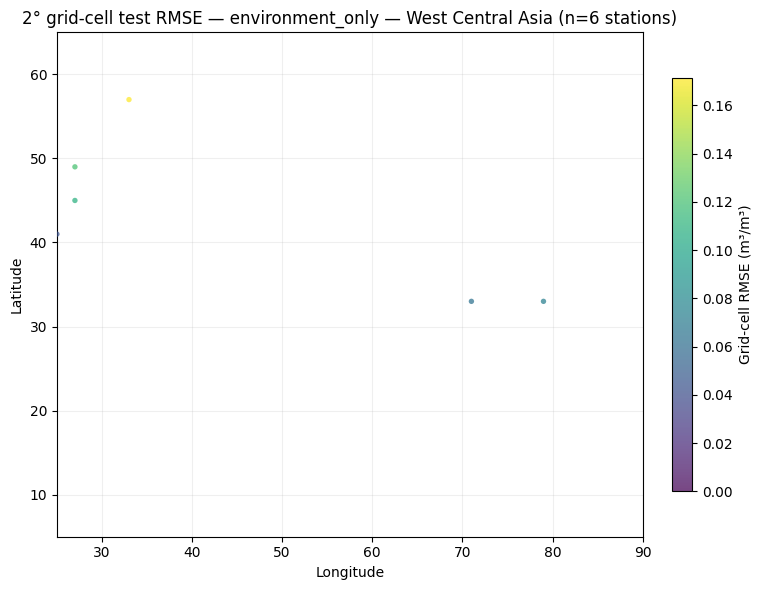

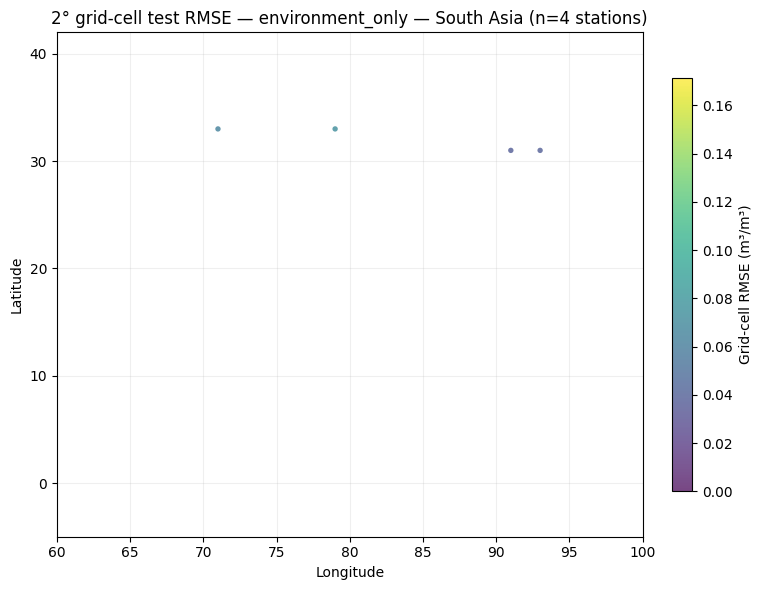

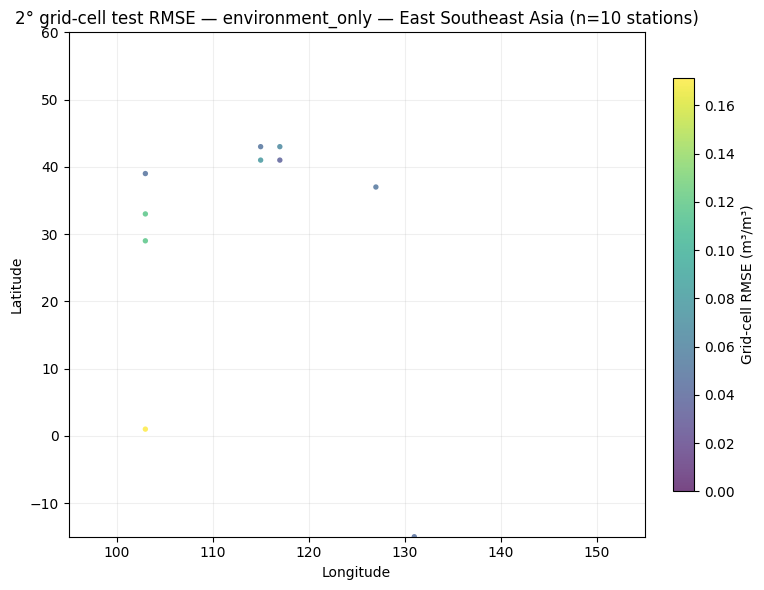

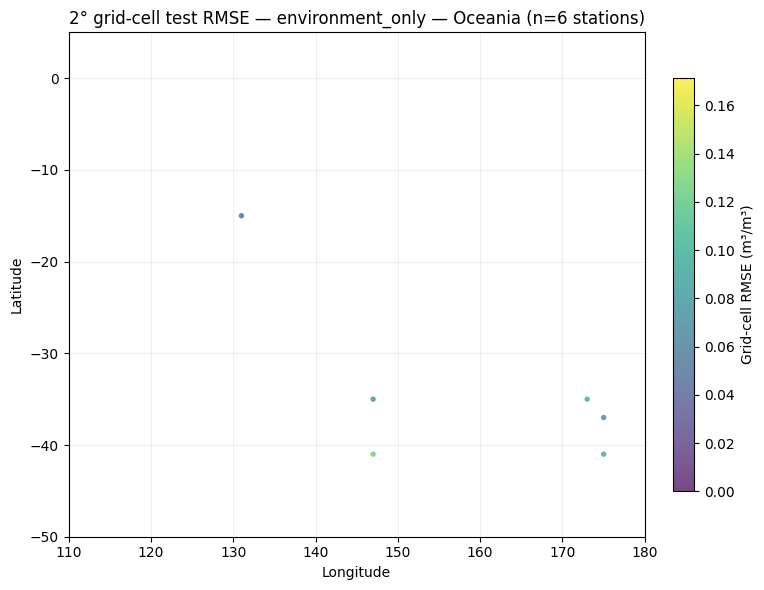

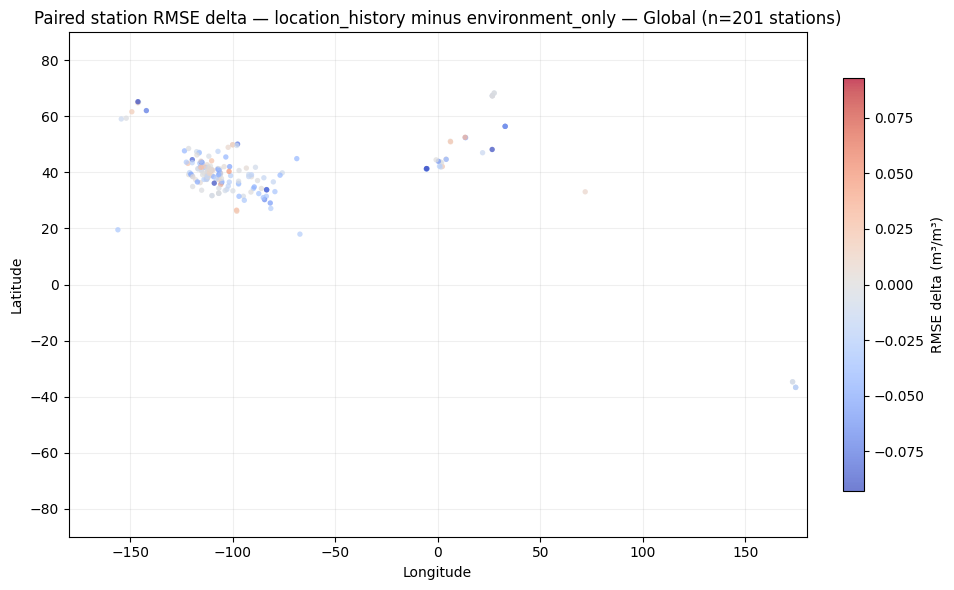

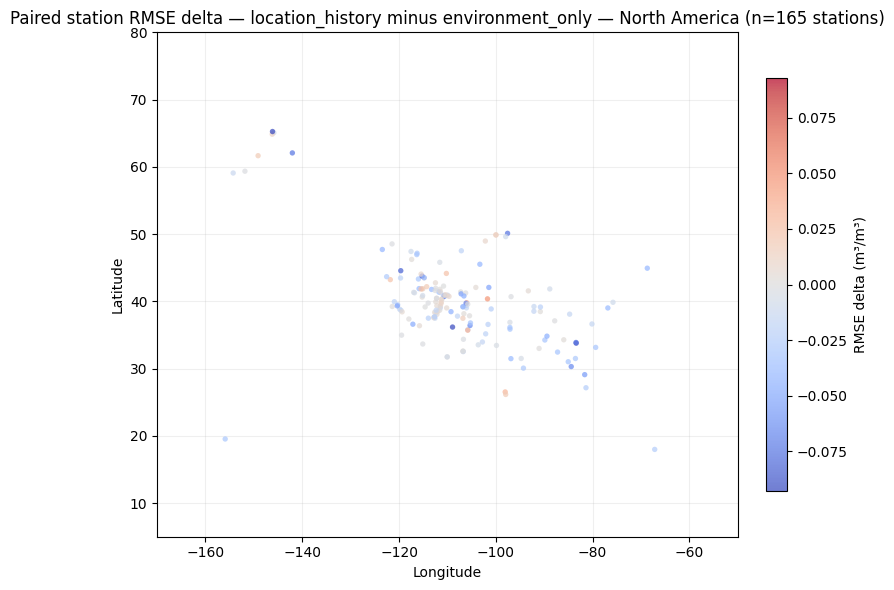

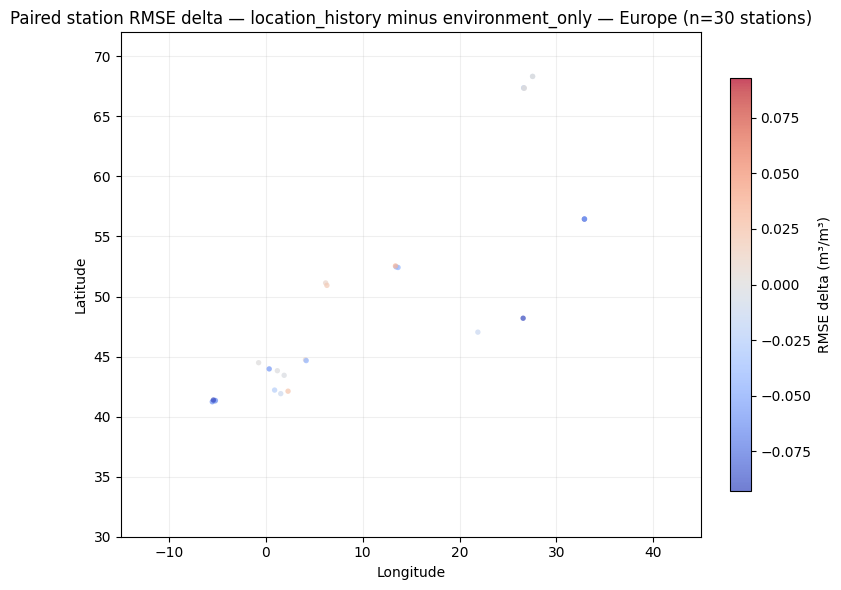

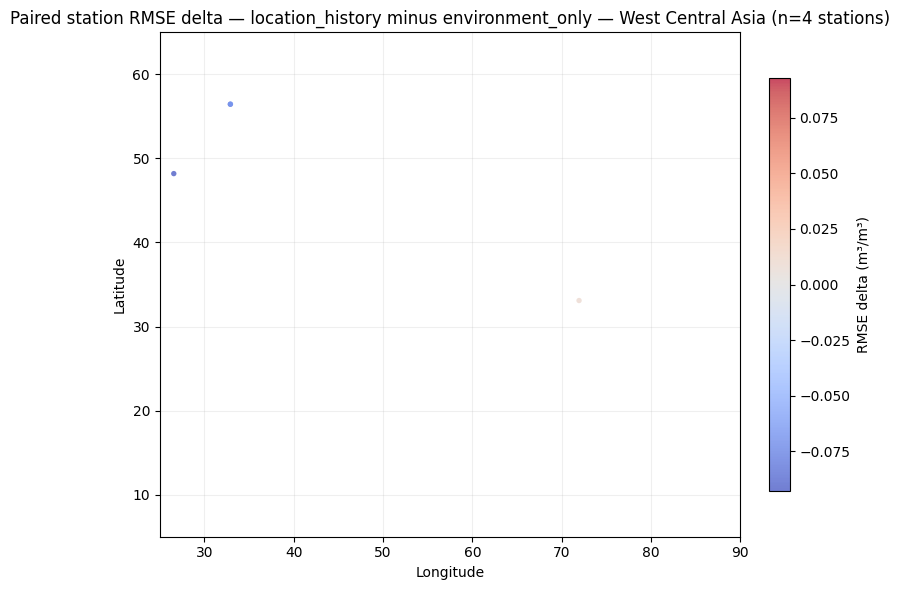

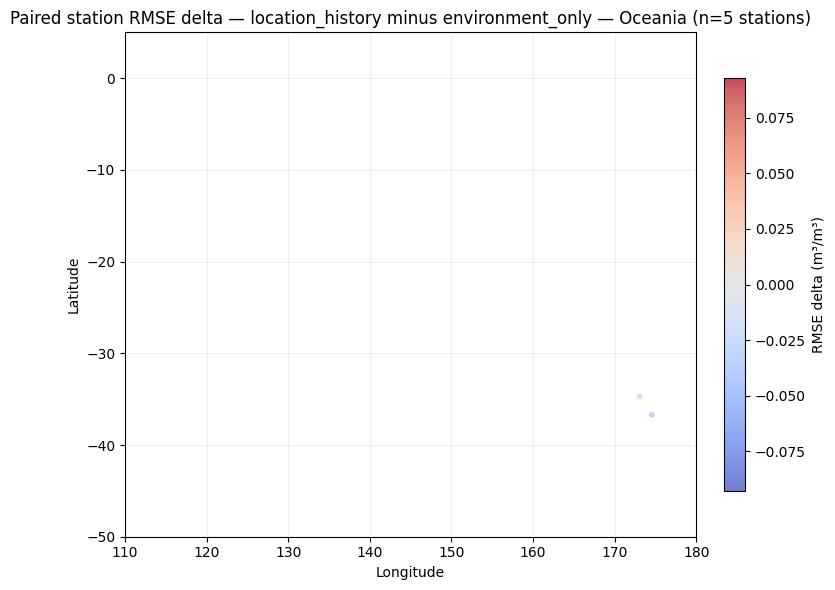

In [10]:
# 10. Fine station maps and grid-cell error summaries for test
# Cartopy supplies Natural Earth country borders. It is optional: without it, the
# notebook still creates coordinate plots and prints the installation instruction.
try:
    import cartopy.crs as ccrs
    import cartopy.feature as cfeature
    CARTOPY_AVAILABLE = True
except Exception as _cartopy_exc:
    CARTOPY_AVAILABLE = False
    print("Cartopy is not available; maps will be coordinate scatter plots without country borders.")
    print("For country borders, install Cartopy (for example: conda install -c conda-forge cartopy).")

REGION_BOUNDS = {
    "North_America": (-170, -50, 5, 80),
    "South_America": (-85, -30, -60, 15),
    "Europe": (-15, 45, 30, 72),
    "Africa": (-25, 60, -40, 40),
    "West_Central_Asia": (25, 90, 5, 65),
    "South_Asia": (60, 100, -5, 42),
    "East_Southeast_Asia": (95, 155, -15, 60),
    "Oceania": (110, 180, -50, 5),
}


def create_geo_axes(figsize=(9, 6), bounds=(-180, 180, -90, 90)):
    if CARTOPY_AVAILABLE:
        fig = plt.figure(figsize=figsize)
        ax = fig.add_subplot(1, 1, 1, projection=ccrs.PlateCarree())
        ax.set_extent(bounds, crs=ccrs.PlateCarree())
        try:
            ax.add_feature(cfeature.LAND.with_scale("50m"), facecolor="0.94", edgecolor="none", zorder=0)
            ax.add_feature(cfeature.OCEAN.with_scale("50m"), facecolor="white", edgecolor="none", zorder=0)
            ax.add_feature(cfeature.BORDERS.with_scale("50m"), linewidth=0.35,
                           edgecolor="0.35", zorder=1)
            ax.add_feature(cfeature.COASTLINE.with_scale("50m"), linewidth=0.4,
                           edgecolor="0.25", zorder=1)
        except Exception as feature_exc:
            print("Could not load 50m Natural Earth features; trying 110m borders:", feature_exc)
            try:
                ax.add_feature(cfeature.BORDERS.with_scale("110m"), linewidth=0.45,
                               edgecolor="0.35", zorder=1)
                ax.add_feature(cfeature.COASTLINE.with_scale("110m"), linewidth=0.5,
                               edgecolor="0.25", zorder=1)
            except Exception as fallback_exc:
                print("Country-border layer unavailable in this environment:", fallback_exc)
        gl = ax.gridlines(draw_labels=True, linewidth=0.35, color="0.6", alpha=0.35)
        gl.top_labels = False; gl.right_labels = False
        return fig, ax, ccrs.PlateCarree()
    fig, ax = plt.subplots(figsize=figsize)
    ax.set_xlim(bounds[0], bounds[1]); ax.set_ylim(bounds[2], bounds[3])
    ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
    ax.grid(alpha=0.2)
    return fig, ax, None


def plot_station_metric_map(data, value_col, title, filename, cmap=None, vmin=None, vmax=None,
                            colorbar_label=None, regional=True, diverging=False):
    data = data.dropna(subset=["latitude", "longitude", value_col]).copy()
    if data.empty:
        print("No map rows for", title)
        return
    if cmap is None:
        cmap = "coolwarm" if diverging else None
    extents = [("Global", (-180, 180, -90, 90))]
    if regional:
        for region, bounds in REGION_BOUNDS.items():
            lon0, lon1, lat0, lat1 = bounds
            subset = data[data.longitude.between(lon0, lon1) & data.latitude.between(lat0, lat1)]
            if len(subset) >= 2:
                extents.append((region, bounds))
    for region, bounds in extents:
        lon0, lon1, lat0, lat1 = bounds
        d = data[data.longitude.between(lon0, lon1) & data.latitude.between(lat0, lat1)]
        if region == "Global":
            d = data
        if d.empty:
            continue
        fig, ax, transform = create_geo_axes(figsize=(10, 6) if region == "Global" else (8, 6), bounds=bounds)
        scatter_kwargs = dict(c=d[value_col], s=15, alpha=0.72, cmap=cmap,
                             vmin=vmin, vmax=vmax, linewidths=0, rasterized=True, zorder=3)
        if transform is not None:
            scatter_kwargs["transform"] = transform
        sc = ax.scatter(d.longitude, d.latitude, **scatter_kwargs)
        cbar = fig.colorbar(sc, ax=ax, shrink=0.82, pad=0.04)
        cbar.set_label(colorbar_label or value_col)
        suffix = "global" if region == "Global" else region.lower()
        ax.set_title(f"{title} — {region.replace('_', ' ')} (n={len(d):,} stations)")
        fig.tight_layout()
        fig.savefig(PLOTS_DIR / f"{filename}_{suffix}.png", dpi=190, bbox_inches="tight")
        plt.show(); plt.close(fig)

# Use one common colour range across both model station RMSE maps so the colours are comparable.
all_station_rmse = STATION_TEST.rmse_m3_m3.dropna()
common_rmse_max = float(all_station_rmse.quantile(0.98)) if len(all_station_rmse) else None
for mode in ("location_history", "environment_only"):
    st = STATION_TEST[STATION_TEST.task_mode == mode]
    plot_station_metric_map(
        st, "rmse_m3_m3", f"Station-level test RMSE — {mode}",
        f"station_error_map_{mode}_test", cmap="viridis", vmin=0, vmax=common_rmse_max,
        colorbar_label="Station test RMSE (m³/m³)", regional=True,
    )

# Spatial-grid summaries, plotted with the same country-border background and small marks.
spatial_parts = []
for mode, view in [("location_history", VIEWS[("location_history", "test")]),
                   ("environment_only", VIEWS[("environment_only", "test")])]:
    deg = float(SPATIAL_GRID_DEGREES)
    part = DB.execute(f"""
      SELECT '{mode}' AS task_mode,
        FLOOR((latitude + 90.0) / {deg}) * {deg} - 90.0 AS lat_bin,
        FLOOR((longitude + 180.0) / {deg}) * {deg} - 180.0 AS lon_bin,
        COUNT(*)::BIGINT AS n,
        AVG(residual_m3_m3) AS bias_m3_m3,
        AVG(absolute_error_m3_m3) AS mae_m3_m3,
        SQRT(AVG(squared_error_m3_m6)) AS rmse_m3_m3
      FROM {view}
      WHERE latitude BETWEEN -90 AND 90 AND longitude BETWEEN -180 AND 180
        AND isfinite(residual_m3_m3)
      GROUP BY FLOOR((latitude + 90.0) / {deg}) * {deg} - 90.0,
               FLOOR((longitude + 180.0) / {deg}) * {deg} - 180.0
      HAVING COUNT(*) >= {MIN_STATION_ROWS}
    """).df()
    spatial_parts.append(part)
SPATIAL_METRICS = pd.concat(spatial_parts, ignore_index=True)
SPATIAL_METRICS.to_csv(TABLES_DIR / "spatial_grid_metrics_test.csv", index=False)
for mode in ("location_history", "environment_only"):
    grid = SPATIAL_METRICS[SPATIAL_METRICS.task_mode == mode].copy()
    grid["latitude"] = grid.lat_bin + SPATIAL_GRID_DEGREES / 2
    grid["longitude"] = grid.lon_bin + SPATIAL_GRID_DEGREES / 2
    plot_station_metric_map(
        grid, "rmse_m3_m3", f"{SPATIAL_GRID_DEGREES:g}° grid-cell test RMSE — {mode}",
        f"spatial_grid_error_{mode}_test", cmap="viridis", vmin=0, vmax=common_rmse_max,
        colorbar_label="Grid-cell RMSE (m³/m³)", regional=True,
    )

# Where location history helps or hurts: negative delta means lower RMSE for location_history.
coords = DB.execute(f"""
  SELECT network, station_id, AVG(latitude) AS latitude, AVG(longitude) AS longitude,
         COUNT(*)::BIGINT AS n,
         SQRT(AVG(POWER(residual_location,2))) - SQRT(AVG(POWER(residual_environment,2))) AS rmse_delta
  FROM {PAIR_VIEWS['test']}
  WHERE ABS(y_location-y_environment) <= 1e-5
  GROUP BY network, station_id HAVING COUNT(*) >= {MIN_STATION_ROWS}
""").df()
coords.to_csv(TABLES_DIR / "paired_station_rmse_delta_map_data.csv", index=False)
delta_limit = float(coords.rmse_delta.abs().quantile(0.98)) if len(coords) else None
plot_station_metric_map(
    coords, "rmse_delta", "Paired station RMSE delta — location_history minus environment_only",
    "paired_station_rmse_delta_map_test", cmap="coolwarm",
    vmin=-delta_limit if delta_limit else None, vmax=delta_limit,
    colorbar_label="RMSE delta (m³/m³)", regional=True, diverging=True,
)


## 8) Time, seasonality, and moisture-regime diagnostics

These summaries can reveal whether the models struggle in particular years, months, or soil-moisture regimes. Monthly/yearly summaries are computed over the complete exports; the target-bin plots likewise use all rows.

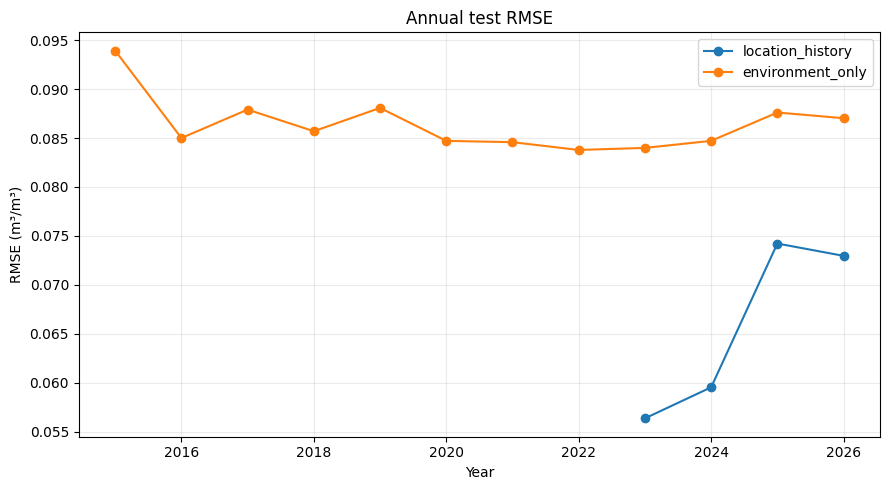

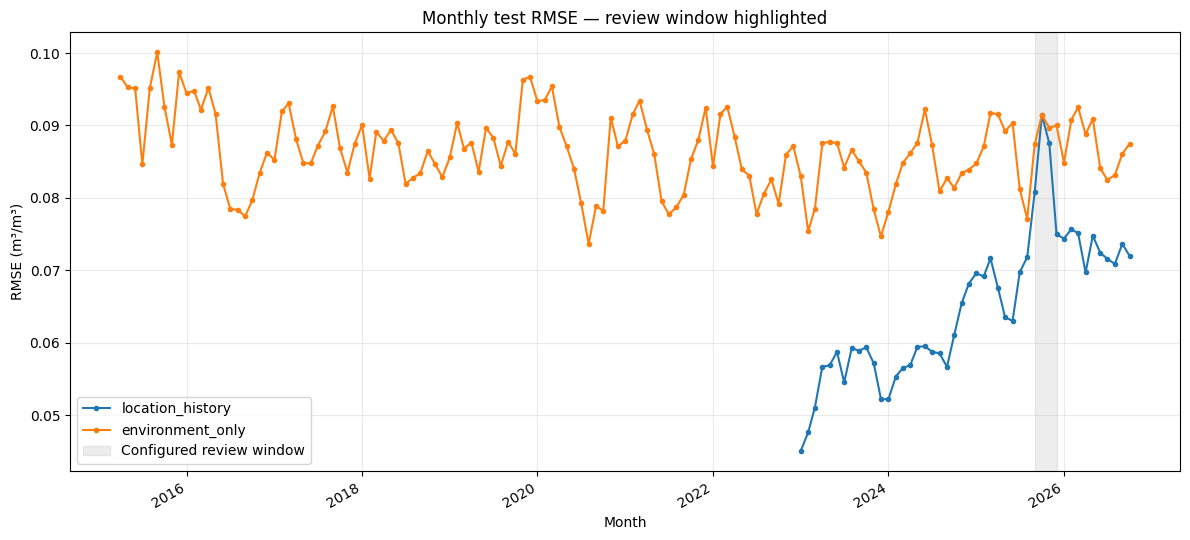

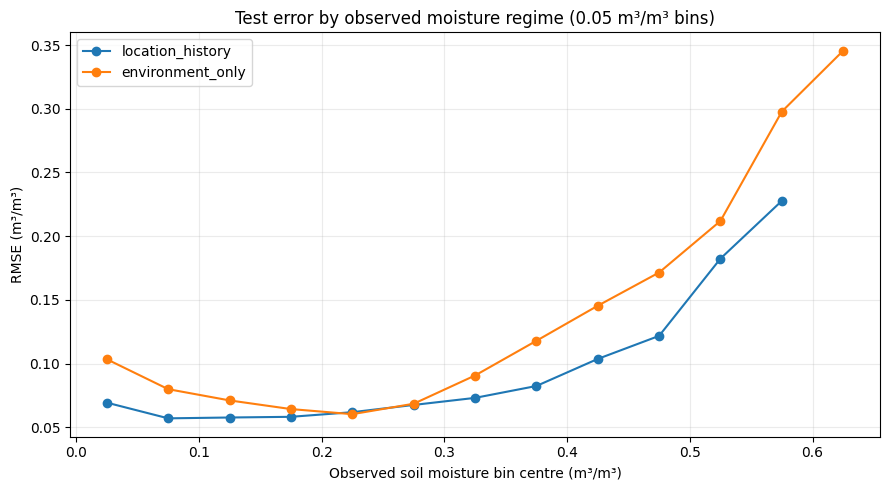

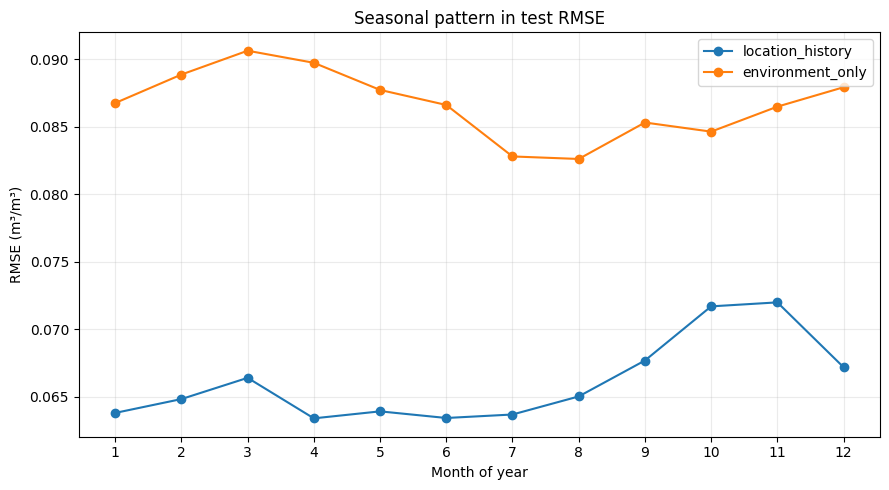

In [11]:
# 11. Annual and monthly test error trends
annual_parts, monthly_parts, target_bin_parts, season_parts = [], [], [], []
for mode, view in [("location_history", VIEWS[("location_history", "test")]),
                   ("environment_only", VIEWS[("environment_only", "test")])]:
    year_expr = "YEAR(CAST(sample_date AS DATE))"
    month_expr = "DATE_TRUNC('month', CAST(sample_date AS DATE))"
    month_of_year_expr = "MONTH(CAST(sample_date AS DATE))"
    target_bin_expr = "FLOOR(y_true_m3_m3 / 0.05) * 0.05"

    # IMPORTANT: group by the full expression, not its SELECT alias. This avoids the
    # DuckDB BinderException seen with GROUP BY year on some versions/schemas.
    annual = DB.execute(f"""
      SELECT '{mode}' AS task_mode, {year_expr} AS year,
             COUNT(*)::BIGINT AS n, AVG(residual_m3_m3) AS bias_m3_m3,
             AVG(absolute_error_m3_m3) AS mae_m3_m3,
             SQRT(AVG(squared_error_m3_m6)) AS rmse_m3_m3
      FROM {view}
      WHERE isfinite(y_true_m3_m3) AND isfinite(residual_m3_m3)
      GROUP BY {year_expr} ORDER BY {year_expr}
    """).df()
    monthly = DB.execute(f"""
      SELECT '{mode}' AS task_mode, {month_expr} AS month,
             COUNT(*)::BIGINT AS n, AVG(residual_m3_m3) AS bias_m3_m3,
             AVG(absolute_error_m3_m3) AS mae_m3_m3,
             SQRT(AVG(squared_error_m3_m6)) AS rmse_m3_m3,
             AVG(y_true_m3_m3) AS mean_observed,
             STDDEV_POP(y_true_m3_m3) AS sd_observed,
             CASE WHEN (SUM(y_true_m3_m3*y_true_m3_m3)
                        - SUM(y_true_m3_m3)*SUM(y_true_m3_m3)/COUNT(*)) > 0
                  THEN 1.0 - SUM(squared_error_m3_m6) /
                       (SUM(y_true_m3_m3*y_true_m3_m3)
                        - SUM(y_true_m3_m3)*SUM(y_true_m3_m3)/COUNT(*))
                  ELSE NULL END AS r2
      FROM {view}
      WHERE isfinite(y_true_m3_m3) AND isfinite(residual_m3_m3)
      GROUP BY {month_expr} ORDER BY {month_expr}
    """).df()
    season = DB.execute(f"""
      SELECT '{mode}' AS task_mode, {month_of_year_expr} AS month_of_year,
             COUNT(*)::BIGINT AS n, AVG(residual_m3_m3) AS bias_m3_m3,
             AVG(absolute_error_m3_m3) AS mae_m3_m3,
             SQRT(AVG(squared_error_m3_m6)) AS rmse_m3_m3
      FROM {view}
      WHERE isfinite(y_true_m3_m3) AND isfinite(residual_m3_m3)
      GROUP BY {month_of_year_expr} ORDER BY {month_of_year_expr}
    """).df()
    bins = DB.execute(f"""
      SELECT '{mode}' AS task_mode,
             {target_bin_expr} AS target_bin_start,
             COUNT(*)::BIGINT AS n,
             AVG(residual_m3_m3) AS bias_m3_m3,
             AVG(absolute_error_m3_m3) AS mae_m3_m3,
             SQRT(AVG(squared_error_m3_m6)) AS rmse_m3_m3
      FROM {view}
      WHERE isfinite(y_true_m3_m3) AND isfinite(residual_m3_m3)
      GROUP BY {target_bin_expr} ORDER BY {target_bin_expr}
    """).df()
    annual_parts.append(annual); monthly_parts.append(monthly)
    target_bin_parts.append(bins); season_parts.append(season)
ANNUAL_METRICS = pd.concat(annual_parts, ignore_index=True)
MONTHLY_METRICS = pd.concat(monthly_parts, ignore_index=True)
TARGET_BIN_METRICS = pd.concat(target_bin_parts, ignore_index=True)
SEASONAL_METRICS = pd.concat(season_parts, ignore_index=True)
ANNUAL_METRICS.to_csv(TABLES_DIR / "annual_metrics_test.csv", index=False)
MONTHLY_METRICS.to_csv(TABLES_DIR / "monthly_metrics_test.csv", index=False)
TARGET_BIN_METRICS.to_csv(TABLES_DIR / "target_moisture_bin_metrics_test.csv", index=False)
SEASONAL_METRICS.to_csv(TABLES_DIR / "month_of_year_metrics_test.csv", index=False)

def plot_monthly_metric(data, metric, ylabel, title, filename):
    fig, ax = plt.subplots(figsize=(12, 5.5))
    for mode in ("location_history", "environment_only"):
        d = data[data.task_mode == mode].sort_values("month")
        ax.plot(pd.to_datetime(d.month), d[metric], marker="o", markersize=3,
                linewidth=1.5, label=mode)
    ax.axvspan(EVENT_WINDOW_START, EVENT_WINDOW_END + pd.Timedelta(days=1),
               color="grey", alpha=0.14, label="Configured review window")
    ax.set_xlabel("Month"); ax.set_ylabel(ylabel); ax.set_title(title)
    ax.legend(); ax.grid(alpha=0.25); fig.autofmt_xdate(); fig.tight_layout()
    fig.savefig(PLOTS_DIR / filename, dpi=180); plt.show(); plt.close(fig)

fig, ax = plt.subplots(figsize=(9, 5))
for mode in ("location_history", "environment_only"):
    d = ANNUAL_METRICS[ANNUAL_METRICS.task_mode == mode]
    ax.plot(d.year, d.rmse_m3_m3, marker="o", label=mode)
ax.set_xlabel("Year"); ax.set_ylabel("RMSE (m³/m³)")
ax.set_title("Annual test RMSE"); ax.legend(); ax.grid(alpha=0.25)
fig.tight_layout(); fig.savefig(PLOTS_DIR / "annual_test_rmse.png", dpi=170)
plt.show(); plt.close(fig)
plot_monthly_metric(MONTHLY_METRICS, "rmse_m3_m3", "RMSE (m³/m³)",
                    "Monthly test RMSE — review window highlighted", "monthly_test_rmse.png")

fig, ax = plt.subplots(figsize=(9, 5))
for mode in ("location_history", "environment_only"):
    d = TARGET_BIN_METRICS[TARGET_BIN_METRICS.task_mode == mode]
    centers = d.target_bin_start + 0.025
    ax.plot(centers, d.rmse_m3_m3, marker="o", label=mode)
ax.set_xlabel("Observed soil moisture bin centre (m³/m³)")
ax.set_ylabel("RMSE (m³/m³)")
ax.set_title("Test error by observed moisture regime (0.05 m³/m³ bins)")
ax.legend(); ax.grid(alpha=0.25); fig.tight_layout()
fig.savefig(PLOTS_DIR / "test_rmse_by_moisture_bin.png", dpi=170); plt.show(); plt.close(fig)

fig, ax = plt.subplots(figsize=(9, 5))
for mode in ("location_history", "environment_only"):
    d = SEASONAL_METRICS[SEASONAL_METRICS.task_mode == mode]
    ax.plot(d.month_of_year, d.rmse_m3_m3, marker="o", label=mode)
ax.set_xticks(range(1, 13)); ax.set_xlabel("Month of year")
ax.set_ylabel("RMSE (m³/m³)"); ax.set_title("Seasonal pattern in test RMSE")
ax.legend(); ax.grid(alpha=0.25); fig.tight_layout()
fig.savefig(PLOTS_DIR / "month_of_year_test_rmse.png", dpi=170); plt.show(); plt.close(fig)


## 12) Investigate the late-2025 error spike: is it localised, persistent, or composition-driven?

The review window defaults to **1 September–30 November 2025**, centred around the spike visible in the supplied monthly chart. Change `EVENT_WINDOW_START` / `EVENT_WINDOW_END` in the settings cell to investigate another interval. This section compares full test performance, performance inside the window, and performance outside it; identifies statistically unusual months using a robust median/MAD screen; and lists stations/networks contributing most of the window's error.

The excluded-window score answers: *what would the test score have been on the remaining dates?* It does not prove that those dates are invalid or that the spike has a particular cause. The station/network and target-distribution tables are clues for diagnosis, not causal evidence.


,n,n_stations,bias_m3_m3,mae_m3_m3,rmse_m3_m3,r2,mean_observed,sd_observed,task_mode,segment,window_start,window_end,pct_of_full_test
0,905248.0,1028.0,0.00123,0.04854,0.06594,0.65341,0.17749,0.11200,location_history,full_test,2025-09-01,2025-11-30,100.00000
1,67604.0,818.0,-0.03212,0.06563,0.08666,0.29330,0.17013,0.10309,location_history,review_window,2025-09-01,2025-11-30,7.46801
2,837644.0,1028.0,0.00392,0.04715,0.06397,0.67761,0.17809,0.11267,location_history,outside_review_window,2025-09-01,2025-11-30,92.53199
3,644716.0,444.0,0.00405,0.06794,0.08626,0.47046,0.18711,0.11854,environment_only,full_test,2025-09-01,2025-11-30,100.00000
4,14776.0,181.0,-0.00323,0.06983,0.08949,0.27755,0.17312,0.10529,environment_only,review_window,2025-09-01,2025-11-30,2.29186
5,629940.0,444.0,0.00422,0.06790,0.08618,0.47383,0.18744,0.11881,environment_only,outside_review_window,2025-09-01,2025-11-30,97.70814


Matched-observation comparison inside vs outside the review window:


,segment,n,location_rmse,location_mae,location_bias,location_r2,environment_rmse,environment_mae,environment_bias,environment_r2,location_minus_environment_mae
0,outside_review_window,169314,0.06466,0.04779,0.00240,0.69067,0.0847,0.06653,0.00641,0.46931,-0.01874
1,review_window,13214,0.09224,0.06906,-0.03961,0.20916,0.0875,0.06798,-0.00540,0.28836,0.00108


Months above the robust median/MAD threshold:


,task_mode,month,n,bias_m3_m3,mae_m3_m3,rmse_m3_m3,mean_observed,sd_observed,r2,median_rmse,mad_rmse,robust_threshold,robust_z,is_robust_anomaly
51,environment_only,2015-09-01,3399,-0.00412,0.07843,0.10011,0.19094,0.12201,0.32682,0.08686,0.00352,0.09992,2.53616,True
33,location_history,2025-10-01,23612,-0.03875,0.07054,0.09145,0.18051,0.10251,0.20411,0.06324,0.00668,0.08800,2.84815,True


Top stations by total absolute error inside the configured window:

 location_history


... (4 outputs left out)

,task_mode,network,n,n_stations,bias_m3_m3,mae_m3_m3,rmse_m3_m3,total_absolute_error
0,location_history,SNOTEL,33776,412,-0.04130,0.07886,0.09962,2663.73304
1,location_history,SCAN,16737,197,-0.01857,0.05100,0.06855,853.56954
2,location_history,USCRN,6201,71,-0.00641,0.04343,0.05759,269.31844
3,location_history,Berlin,2049,23,-0.02651,0.05652,0.07450,115.81782
4,location_history,XMS-CAT,1266,14,-0.06640,0.07951,0.10718,100.65744
5,location_history,FMI,1201,15,-0.03856,0.08112,0.11191,97.42247
6,location_history,RISMA,1569,20,-0.03367,0.05221,0.06474,81.92426
7,location_history,SOILSCAPE,1560,19,-0.03123,0.03943,0.05040,61.50941
8,location_history,CW3E,889,11,-0.04396,0.05811,0.08258,51.66241
9,location_history,TERENO,405,5,-0.09921,0.09990,0.10938,40.46078


Stations with the largest RMSE increase inside the window vs the same station outside it:


,task_mode,network,station_id,bias_m3_m3_outside_review_window,bias_m3_m3_review_window,mae_m3_m3_outside_review_window,mae_m3_m3_review_window,n_outside_review_window,n_review_window,rmse_m3_m3_outside_review_window,rmse_m3_m3_review_window,rmse_change_inside_minus_outside
1101,location_history,SNOTEL,SNOTEL__Mormon_Mountain,0.03722,0.29250,0.07868,0.29250,782.0,11.0,0.11720,0.29265,0.17545
1001,location_history,SNOTEL,SNOTEL__Heavenly_Valley,-0.08195,-0.28184,0.08528,0.28184,958.0,89.0,0.12177,0.29179,0.17002
1125,location_history,SNOTEL,SNOTEL__Park_Cone,-0.01822,-0.23057,0.05607,0.23258,749.0,63.0,0.07169,0.23731,0.16562
892,location_history,SNOTEL,SNOTEL__Buck_Pasture,-0.03818,-0.24507,0.06365,0.24507,668.0,59.0,0.08863,0.25085,0.16222
1179,location_history,SNOTEL,SNOTEL__Sharkstooth,-0.00722,-0.22714,0.05597,0.22714,730.0,66.0,0.07625,0.23082,0.15458
1083,location_history,SNOTEL,SNOTEL__Mcneil_River_SGS,-0.05720,-0.25031,0.07280,0.25031,500.0,55.0,0.10007,0.25106,0.15100
1040,location_history,SNOTEL,SNOTEL__Lakefork_Basin,-0.03531,-0.22811,0.06910,0.22811,541.0,67.0,0.09394,0.23637,0.14242
973,location_history,SNOTEL,SNOTEL__Galena_AK,0.02291,0.20682,0.04443,0.20682,597.0,46.0,0.06809,0.20831,0.14022
1455,location_history,XMS-CAT,XMS-CAT__Clot_de_les_Peres_II,0.01480,-0.21576,0.08056,0.21576,1262.0,91.0,0.09610,0.23058,0.13448
1121,location_history,SNOTEL,SNOTEL__Palisades_Tahoe,-0.01052,-0.18768,0.04970,0.18768,819.0,55.0,0.06456,0.19652,0.13195


,task_mode,network,station_id,bias_m3_m3_outside_review_window,bias_m3_m3_review_window,mae_m3_m3_outside_review_window,mae_m3_m3_review_window,n_outside_review_window,n_review_window,rmse_m3_m3_outside_review_window,rmse_m3_m3_review_window,rmse_change_inside_minus_outside
52,environment_only,CW3E,CW3E__Browns_Valley_School,-0.03843,-0.19388,0.05771,0.19388,1903.0,89.0,0.07659,0.19803,0.12144
247,environment_only,SNOTEL,SNOTEL__Box_Springs,0.04194,-0.15359,0.05609,0.15359,2321.0,71.0,0.07117,0.16520,0.09403
258,environment_only,SNOTEL,SNOTEL__Css_Lab,0.07650,0.15886,0.08530,0.15886,2749.0,91.0,0.10329,0.17147,0.06817
335,environment_only,SOILSCAPE,SOILSCAPE__CO-Z4_2101,-0.04270,-0.10095,0.04301,0.10095,486.0,17.0,0.05254,0.11457,0.06203
272,environment_only,SNOTEL,SNOTEL__Hole-in-Rock,0.05051,0.13548,0.07196,0.13548,1942.0,88.0,0.08616,0.14590,0.05974
67,environment_only,FMI,FMI__SOD071,-0.01572,-0.12113,0.04772,0.12113,2073.0,91.0,0.06614,0.12247,0.05633
314,environment_only,SNOTEL,SNOTEL__Seven_Mile,0.15780,0.21664,0.15780,0.21664,84.0,47.0,0.16112,0.21742,0.05629
329,environment_only,SNOTEL,SNOTEL__Wildhorse_Divide,-0.02828,-0.14298,0.06894,0.14298,1456.0,91.0,0.09156,0.14784,0.05628
15,environment_only,Berlin,Berlin__PflABerlin11Humb,-0.07610,-0.13674,0.07880,0.13674,1227.0,91.0,0.08869,0.13857,0.04988
215,environment_only,SCAN,SCAN__Riesel,-0.03818,-0.13169,0.08107,0.13169,2297.0,90.0,0.09918,0.14405,0.04488


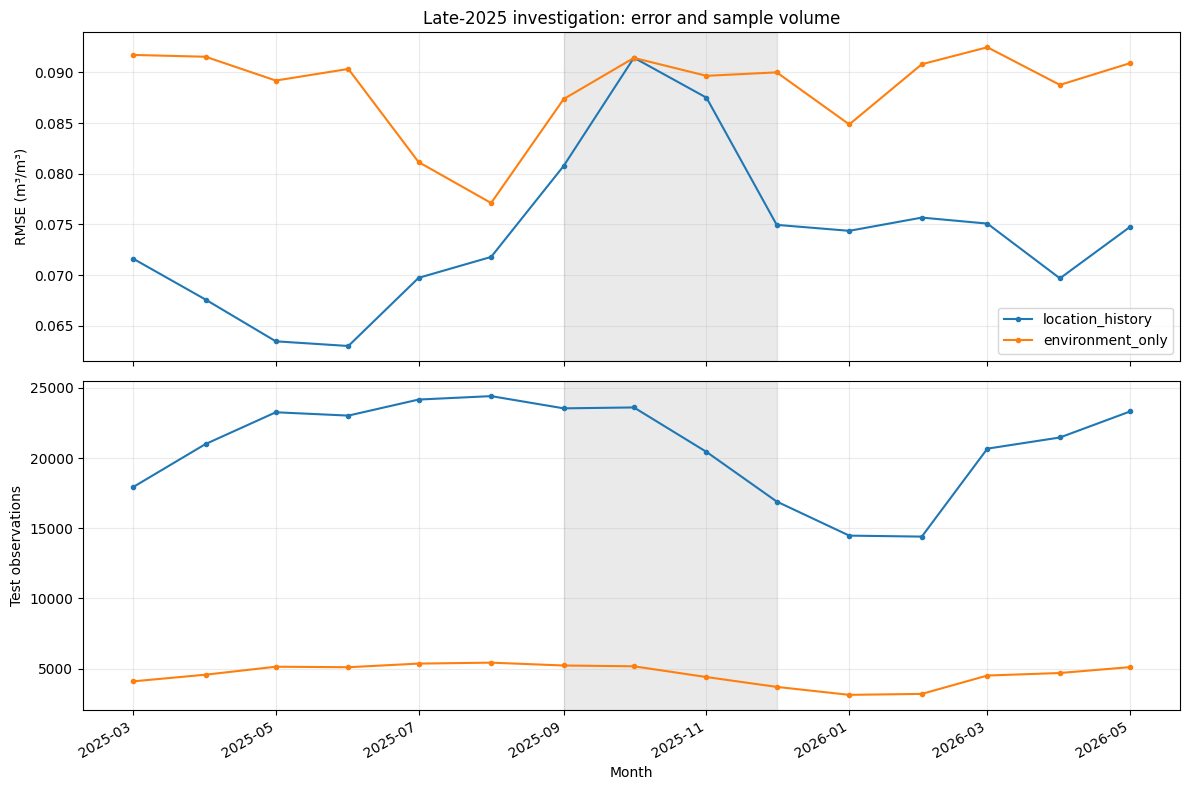


SPIKE INTERPRETATION CHECK
location_history: window rows=67,604 (7.47% of test); window RMSE=0.08666; outside RMSE=0.06397; full R²=0.65341; outside-window R²=0.67761; robust-anomaly months=['2025-10']
environment_only: window rows=14,776 (2.29% of test); window RMSE=0.08949; outside RMSE=0.08618; full R²=0.47046; outside-window R²=0.47383; robust-anomaly months=['2015-09']


In [12]:
# 12A. Full test vs review-window vs outside-window metrics
_event_start = EVENT_WINDOW_START.date().isoformat()
_event_end_exclusive = (EVENT_WINDOW_END + pd.Timedelta(days=1)).date().isoformat()
_event_predicate = (f"CAST(sample_date AS DATE) >= DATE '{_event_start}' "
                    f"AND CAST(sample_date AS DATE) < DATE '{_event_end_exclusive}'")


def subset_metrics(view, where_sql="TRUE"):
    return DB.execute(f"""
      SELECT COUNT(*)::BIGINT AS n,
             COUNT(DISTINCT station_key)::BIGINT AS n_stations,
             AVG(residual_m3_m3) AS bias_m3_m3,
             AVG(absolute_error_m3_m3) AS mae_m3_m3,
             SQRT(AVG(POWER(residual_m3_m3, 2))) AS rmse_m3_m3,
             CASE WHEN (SUM(y_true_m3_m3*y_true_m3_m3)
                        - SUM(y_true_m3_m3)*SUM(y_true_m3_m3)/COUNT(*)) > 0
                  THEN 1.0 - SUM(POWER(residual_m3_m3,2)) /
                       (SUM(y_true_m3_m3*y_true_m3_m3)
                        - SUM(y_true_m3_m3)*SUM(y_true_m3_m3)/COUNT(*))
                  ELSE NULL END AS r2,
             AVG(y_true_m3_m3) AS mean_observed,
             STDDEV_POP(y_true_m3_m3) AS sd_observed
      FROM {view}
      WHERE ({where_sql})
        AND isfinite(y_true_m3_m3) AND isfinite(residual_m3_m3)
        AND isfinite(absolute_error_m3_m3)
    """).df().iloc[0].to_dict()

_event_rows = []
for mode in ("location_history", "environment_only"):
    view = VIEWS[(mode, "test")]
    for segment, predicate in [
        ("full_test", "TRUE"),
        ("review_window", _event_predicate),
        ("outside_review_window", f"NOT ({_event_predicate})"),
    ]:
        r = subset_metrics(view, predicate)
        r.update(task_mode=mode, segment=segment,
                 window_start=_event_start, window_end=EVENT_WINDOW_END.date().isoformat())
        _event_rows.append(r)
EVENT_EXCLUSION_METRICS = pd.DataFrame(_event_rows)
EVENT_EXCLUSION_METRICS["pct_of_full_test"] = EVENT_EXCLUSION_METRICS.apply(
    lambda r: 100.0 * r.n / EVENT_EXCLUSION_METRICS[
        (EVENT_EXCLUSION_METRICS.task_mode == r.task_mode) &
        (EVENT_EXCLUSION_METRICS.segment == "full_test")].n.iloc[0]
    if r.segment != "full_test" else 100.0, axis=1)
EVENT_EXCLUSION_METRICS.to_csv(TABLES_DIR / "event_window_inclusion_exclusion_metrics.csv", index=False)
display(EVENT_EXCLUSION_METRICS.round(5))

# Repeat the inside/outside comparison on the intersection of both models' test rows.
# This is the fairest test of whether the spike affects one model more than the other.
EVENT_PAIRED_METRICS = DB.execute(f"""
  SELECT CASE WHEN sample_date >= DATE '{_event_start}'
                   AND sample_date < DATE '{_event_end_exclusive}'
              THEN 'review_window' ELSE 'outside_review_window' END AS segment,
         COUNT(*)::BIGINT AS n,
         SQRT(AVG(POWER(residual_location,2))) AS location_rmse,
         AVG(ABS(residual_location)) AS location_mae,
         AVG(residual_location) AS location_bias,
         CASE WHEN (SUM(y_location*y_location)-SUM(y_location)*SUM(y_location)/COUNT(*)) > 0
              THEN 1.0-SUM(POWER(residual_location,2))/
                   (SUM(y_location*y_location)-SUM(y_location)*SUM(y_location)/COUNT(*))
              ELSE NULL END AS location_r2,
         SQRT(AVG(POWER(residual_environment,2))) AS environment_rmse,
         AVG(ABS(residual_environment)) AS environment_mae,
         AVG(residual_environment) AS environment_bias,
         CASE WHEN (SUM(y_environment*y_environment)-SUM(y_environment)*SUM(y_environment)/COUNT(*)) > 0
              THEN 1.0-SUM(POWER(residual_environment,2))/
                   (SUM(y_environment*y_environment)-SUM(y_environment)*SUM(y_environment)/COUNT(*))
              ELSE NULL END AS environment_r2,
         AVG(ABS(residual_location)-ABS(residual_environment)) AS location_minus_environment_mae
  FROM {PAIR_VIEWS['test']}
  WHERE ABS(y_location-y_environment) <= 1e-5
    AND isfinite(y_location) AND isfinite(residual_location) AND isfinite(residual_environment)
  GROUP BY CASE WHEN sample_date >= DATE '{_event_start}'
                     AND sample_date < DATE '{_event_end_exclusive}'
                THEN 'review_window' ELSE 'outside_review_window' END
  ORDER BY segment
""").df()
EVENT_PAIRED_METRICS.to_csv(TABLES_DIR / "event_window_paired_metrics.csv", index=False)
print("Matched-observation comparison inside vs outside the review window:")
display(EVENT_PAIRED_METRICS.round(5))

# Robust month flags: median + 2.5 * (1.4826 * MAD). This is a screening heuristic,
# not a formal change-point test; use the actual monthly counts and adjacent months too.
_anomaly_rows = []
for mode in ("location_history", "environment_only"):
    d = MONTHLY_METRICS[MONTHLY_METRICS.task_mode == mode].copy()
    d["month"] = pd.to_datetime(d.month)
    d = d[d.n >= MIN_MONTH_ROWS].copy()
    if d.empty:
        continue
    med = float(d.rmse_m3_m3.median())
    mad = float((d.rmse_m3_m3 - med).abs().median())
    robust_sigma = 1.4826 * mad
    threshold = med + AUTO_ANOMALY_MAD_MULTIPLIER * robust_sigma
    d["median_rmse"] = med
    d["mad_rmse"] = mad
    d["robust_threshold"] = threshold
    d["robust_z"] = (d.rmse_m3_m3 - med) / robust_sigma if robust_sigma > 0 else np.nan
    d["is_robust_anomaly"] = d.rmse_m3_m3 > threshold
    _anomaly_rows.append(d)
ANOMALOUS_MONTHS = (pd.concat(_anomaly_rows, ignore_index=True) if _anomaly_rows
                   else pd.DataFrame(columns=list(MONTHLY_METRICS.columns) +
                                     ["median_rmse", "mad_rmse", "robust_threshold", "robust_z", "is_robust_anomaly"]))
ANOMALOUS_MONTHS = ANOMALOUS_MONTHS.sort_values(["task_mode", "month"])
ANOMALOUS_MONTHS.to_csv(TABLES_DIR / "monthly_robust_anomaly_screen.csv", index=False)
print("Months above the robust median/MAD threshold:")
display(ANOMALOUS_MONTHS[ANOMALOUS_MONTHS.is_robust_anomaly].round(5))

# Window-level station and network composition: high RMSE can be driven by a few
# stations, a change in which stations are represented, or a broad shift.
_event_station_parts = []
_event_network_parts = []
for mode in ("location_history", "environment_only"):
    view = VIEWS[(mode, "test")]
    st = DB.execute(f"""
      SELECT '{mode}' AS task_mode, network, station_id,
             COUNT(*)::BIGINT AS n,
             AVG(latitude) AS latitude, AVG(longitude) AS longitude,
             AVG(y_true_m3_m3) AS mean_observed,
             STDDEV_POP(y_true_m3_m3) AS sd_observed,
             AVG(residual_m3_m3) AS bias_m3_m3,
             AVG(absolute_error_m3_m3) AS mae_m3_m3,
             SQRT(AVG(POWER(residual_m3_m3,2))) AS rmse_m3_m3,
             SUM(absolute_error_m3_m3) AS total_absolute_error
      FROM {view}
      WHERE {_event_predicate}
        AND isfinite(y_true_m3_m3) AND isfinite(residual_m3_m3)
      GROUP BY network, station_id
      ORDER BY total_absolute_error DESC
    """).df()
    net = DB.execute(f"""
      SELECT '{mode}' AS task_mode, network,
             COUNT(*)::BIGINT AS n,
             COUNT(DISTINCT station_id)::BIGINT AS n_stations,
             AVG(residual_m3_m3) AS bias_m3_m3,
             AVG(absolute_error_m3_m3) AS mae_m3_m3,
             SQRT(AVG(POWER(residual_m3_m3,2))) AS rmse_m3_m3,
             SUM(absolute_error_m3_m3) AS total_absolute_error
      FROM {view}
      WHERE {_event_predicate}
        AND isfinite(y_true_m3_m3) AND isfinite(residual_m3_m3)
      GROUP BY network ORDER BY total_absolute_error DESC
    """).df()
    _event_station_parts.append(st); _event_network_parts.append(net)
EVENT_WINDOW_STATIONS = pd.concat(_event_station_parts, ignore_index=True)
EVENT_WINDOW_NETWORKS = pd.concat(_event_network_parts, ignore_index=True)
EVENT_WINDOW_STATIONS.to_csv(TABLES_DIR / "event_window_station_metrics.csv", index=False)
EVENT_WINDOW_NETWORKS.to_csv(TABLES_DIR / "event_window_network_metrics.csv", index=False)

# Crucial diagnostic: compare each station with itself inside vs outside the window.
# This separates a within-station deterioration from a change in which stations appear.
_station_segment_parts = []
for mode in ("location_history", "environment_only"):
    view = VIEWS[(mode, "test")]
    seg = DB.execute(f"""
      SELECT '{mode}' AS task_mode, network, station_id,
             CASE WHEN {_event_predicate} THEN 'review_window'
                  ELSE 'outside_review_window' END AS segment,
             COUNT(*)::BIGINT AS n,
             AVG(residual_m3_m3) AS bias_m3_m3,
             AVG(absolute_error_m3_m3) AS mae_m3_m3,
             SQRT(AVG(POWER(residual_m3_m3,2))) AS rmse_m3_m3
      FROM {view}
      WHERE isfinite(y_true_m3_m3) AND isfinite(residual_m3_m3)
      GROUP BY network, station_id,
               CASE WHEN {_event_predicate} THEN 'review_window'
                    ELSE 'outside_review_window' END
    """).df()
    _station_segment_parts.append(seg)
EVENT_STATION_SEGMENTS = pd.concat(_station_segment_parts, ignore_index=True)
EVENT_STATION_PIVOT = EVENT_STATION_SEGMENTS.pivot_table(
    index=["task_mode", "network", "station_id"], columns="segment",
    values=["n", "bias_m3_m3", "mae_m3_m3", "rmse_m3_m3"], aggfunc="first"
)
EVENT_STATION_PIVOT.columns = [f"{metric}_{segment}" for metric, segment in EVENT_STATION_PIVOT.columns]
EVENT_STATION_PIVOT = EVENT_STATION_PIVOT.reset_index()
if "rmse_m3_m3_review_window" in EVENT_STATION_PIVOT and "rmse_m3_m3_outside_review_window" in EVENT_STATION_PIVOT:
    EVENT_STATION_PIVOT["rmse_change_inside_minus_outside"] = (
        EVENT_STATION_PIVOT["rmse_m3_m3_review_window"] -
        EVENT_STATION_PIVOT["rmse_m3_m3_outside_review_window"]
    )
EVENT_STATION_PIVOT.to_csv(TABLES_DIR / "event_window_station_inside_vs_outside.csv", index=False)

print("Top stations by total absolute error inside the configured window:")
for mode in ("location_history", "environment_only"):
    print("\n", mode)
    display(EVENT_WINDOW_STATIONS[EVENT_WINDOW_STATIONS.task_mode == mode].head(15).round(5))
print("Top networks by total absolute error inside the configured window:")
display(EVENT_WINDOW_NETWORKS.round(5))

print("Stations with the largest RMSE increase inside the window vs the same station outside it:")
for mode in ("location_history", "environment_only"):
    if "rmse_change_inside_minus_outside" in EVENT_STATION_PIVOT.columns:
        display(EVENT_STATION_PIVOT[EVENT_STATION_PIVOT.task_mode == mode]
                .dropna(subset=["rmse_change_inside_minus_outside"])
                .sort_values("rmse_change_inside_minus_outside", ascending=False)
                .head(15).round(5))

# Month-by-month context around the configured window, including counts and target spread.
_context_start = EVENT_WINDOW_START - pd.DateOffset(months=6)
_context_end = EVENT_WINDOW_END + pd.DateOffset(months=6)
EVENT_MONTHLY_CONTEXT = MONTHLY_METRICS.copy()
EVENT_MONTHLY_CONTEXT["month"] = pd.to_datetime(EVENT_MONTHLY_CONTEXT.month)
EVENT_MONTHLY_CONTEXT = EVENT_MONTHLY_CONTEXT[
    EVENT_MONTHLY_CONTEXT.month.between(_context_start, _context_end)
].copy()
EVENT_MONTHLY_CONTEXT.to_csv(TABLES_DIR / "event_window_monthly_context.csv", index=False)

fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
for ax, metric, ylabel in [(axes[0], "rmse_m3_m3", "RMSE (m³/m³)"),
                           (axes[1], "n", "Test observations")]:
    for mode in ("location_history", "environment_only"):
        d = EVENT_MONTHLY_CONTEXT[EVENT_MONTHLY_CONTEXT.task_mode == mode].sort_values("month")
        ax.plot(d.month, d[metric], marker="o", markersize=3, label=mode)
    ax.axvspan(EVENT_WINDOW_START, EVENT_WINDOW_END + pd.Timedelta(days=1),
               color="grey", alpha=0.16)
    ax.set_ylabel(ylabel); ax.grid(alpha=0.25)
axes[0].set_title("Late-2025 investigation: error and sample volume")
axes[0].legend(); axes[1].set_xlabel("Month")
fig.autofmt_xdate(); fig.tight_layout()
fig.savefig(PLOTS_DIR / "late_2025_spike_context.png", dpi=180); plt.show(); plt.close(fig)

# A compact automated readout: anomaly count and the score change outside the window.
print("\nSPIKE INTERPRETATION CHECK")
for mode in ("location_history", "environment_only"):
    q = EVENT_EXCLUSION_METRICS[EVENT_EXCLUSION_METRICS.task_mode == mode].set_index("segment")
    full = q.loc["full_test"]; inside = q.loc["review_window"]; outside = q.loc["outside_review_window"]
    flags = ANOMALOUS_MONTHS[(ANOMALOUS_MONTHS.task_mode == mode) & ANOMALOUS_MONTHS.is_robust_anomaly]
    print(f"{mode}: window rows={int(inside.n):,} ({inside.pct_of_full_test:.2f}% of test); "
          f"window RMSE={inside.rmse_m3_m3:.5f}; outside RMSE={outside.rmse_m3_m3:.5f}; "
          f"full R²={full.r2:.5f}; outside-window R²={outside.r2:.5f}; "
          f"robust-anomaly months={list(pd.to_datetime(flags.month).dt.strftime('%Y-%m'))}")


## 13) High-error trimming sensitivity: how much of the test set must be discarded to reach R² = 0.7 / 0.8 / 0.9?

For each model, this section ranks test observations from **largest to smallest absolute error**, removes them cumulatively, and recomputes R² on the retained observations. It reports the first removal percentage at which each target is reached, plus the number retained. It also identifies which months and stations dominate the worst 1% of errors.

This is deliberately labelled a **what-if / selective-retention curve**. It is optimistic because it chooses exclusions using the test residuals themselves. Do **not** present the trimmed R² as the model's test performance. The full test metrics remain the correct headline metrics. If a large fraction must be removed, that is evidence of heterogeneous failure modes, not a reason to silently discard difficult cases.


Percentage of highest-error test observations that would need to be discarded:


,task_mode,baseline_test_r2,target_r2,status,pct_test_rows_removed,rows_removed,rows_retained,r2_at_reported_point_or_limit,max_removal_pct_evaluated
0,location_history,0.65341,0.7,reached,1.29998,11768.0,893480.0,0.70126,94.99993
1,location_history,0.65341,0.8,reached,7.89993,71514.0,833734.0,0.80011,94.99993
2,location_history,0.65341,0.9,reached,24.09992,218164.0,687084.0,0.90033,94.99993
3,environment_only,0.47046,0.7,reached,16.79996,108312.0,536404.0,0.70004,94.99997
4,environment_only,0.47046,0.8,reached,32.29996,208243.0,436473.0,0.80046,94.99997
5,environment_only,0.47046,0.9,reached,54.09994,348791.0,295925.0,0.90037,94.99997


Months overrepresented in the worst 1% of test errors:


,task_mode,month,n_worst_1pct,total_abs_error,mean_abs_error
0,location_history,2025-10,821,197.02228,0.23998
1,location_history,2025-09,680,165.66507,0.24363
2,location_history,2025-11,603,145.96003,0.24206
3,location_history,2025-08,501,125.23671,0.24997
4,location_history,2026-06,345,86.49307,0.25070
...,...,...,...,...,...
175,environment_only,2023-02,5,1.29354,0.25871
176,environment_only,2020-10,4,1.03281,0.25820
177,environment_only,2024-12,4,0.98677,0.24669
178,environment_only,2022-01,1,0.23913,0.23913


Stations overrepresented in the worst 1% of test errors (first 20 per model):


,task_mode,network,station_id,n_worst_1pct,total_abs_error,mean_abs_error,mean_residual
0,location_history,SCAN,SCAN__Guilarte_Forest,294,73.99238,0.25167,-0.25167
1,location_history,SNOTEL,SNOTEL__Sheep_Mtn.,227,62.04828,0.27334,0.27144
2,location_history,FMI,FMI__SOD101,224,58.76598,0.26235,-0.26235
3,location_history,USCRN,USCRN__Coos_Bay_8_SW,198,58.15174,0.29370,-0.29370
4,location_history,SCAN,SCAN__Mayday,197,51.57244,0.26179,-0.01250
5,location_history,SNOTEL,SNOTEL__Poison_Flat,178,45.91003,0.25792,-0.25792
6,location_history,SNOTEL,SNOTEL__Heavenly_Valley,170,51.97973,0.30576,-0.30576
7,location_history,SNOTEL,SNOTEL__Elk_Cabin,139,33.12587,0.23832,0.22725
8,location_history,SNOTEL,SNOTEL__MF_Nooksack,136,39.15125,0.28788,0.28788
9,location_history,SCAN,SCAN__Moose_Inc,127,29.63154,0.23332,-0.12453


,task_mode,network,station_id,n_worst_1pct,total_abs_error,mean_abs_error,mean_residual
438,environment_only,SNOTEL,SNOTEL__Navajo_Whiskey_Ck,549,144.70597,0.26358,-0.26358
439,environment_only,SNOTEL,SNOTEL__Buck_Pasture,403,107.96552,0.26790,-0.26790
440,environment_only,Ru_CFR,Ru_CFR__Fyodorovskoye_dry_spruce_stand,327,86.19847,0.26360,-0.26360
441,environment_only,HOBE,HOBE__2.09,268,75.27694,0.28088,-0.28088
442,environment_only,SNOTEL,SNOTEL__Merritt_Mountain,249,70.34814,0.28252,-0.28252
443,environment_only,SNOTEL,SNOTEL__Gold_Basin,240,65.12688,0.27136,-0.27136
444,environment_only,MySMNet,MySMNet__MPOB-BL1,231,65.17486,0.28214,0.28214
445,environment_only,TWENTE,TWENTE__ITCSM_16b,200,58.93094,0.29465,-0.29465
446,environment_only,COSMOS,COSMOS__Howland,183,49.22025,0.26896,-0.26896
447,environment_only,SNOTEL,SNOTEL__Miller_Woods,175,53.31473,0.30466,0.30466


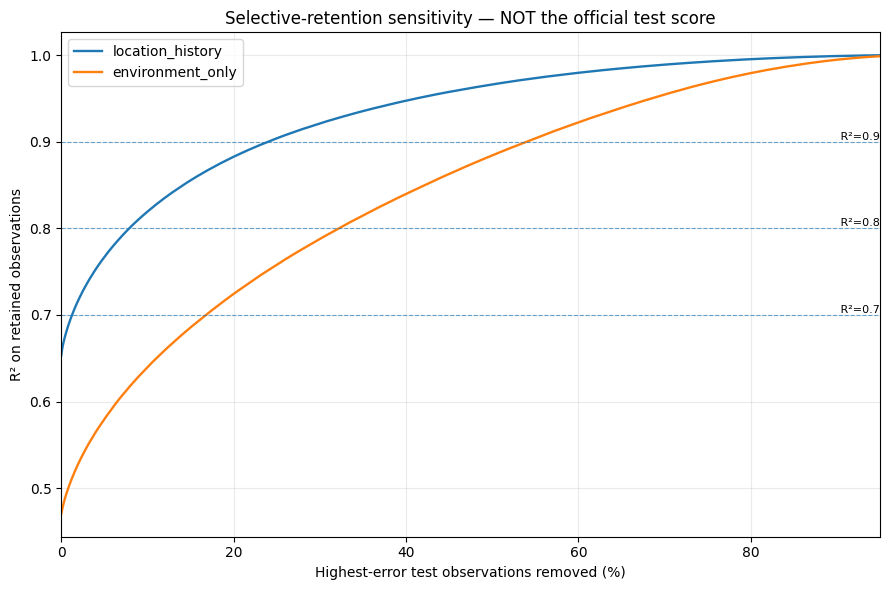

In [13]:
# 13A. Rank the test set by absolute error and build a cumulative R²-vs-removal curve.
# A temp table is materialized once per model so the rank ordering is reused for the
# curve and the top-1% station/month attribution tables.

def make_trim_curve(mode, view):
    temp_name = "trim_rank_" + ("lh" if mode == "location_history" else "eo")
    DB.execute(f"""
      CREATE OR REPLACE TEMP TABLE {temp_name} AS
      SELECT CAST(sample_id AS VARCHAR) AS sample_id,
             network, station_id, CAST(sample_date AS DATE) AS sample_date,
             y_true_m3_m3 AS y,
             residual_m3_m3 AS residual,
             absolute_error_m3_m3 AS abs_error,
             ROW_NUMBER() OVER (
                 ORDER BY absolute_error_m3_m3 DESC, CAST(sample_id AS VARCHAR)
             )::BIGINT AS err_rank,
             COUNT(*) OVER ()::BIGINT AS total_n
      FROM {view}
      WHERE isfinite(y_true_m3_m3) AND isfinite(residual_m3_m3)
        AND isfinite(absolute_error_m3_m3)
    """)

    min_keep = max(int(TRIM_MIN_RETAINED_ROWS), 1)
    bins = int(TRIM_CURVE_BINS)
    max_pct = float(TRIM_MAX_REMOVAL_PCT)
    curve = DB.execute(f"""
      WITH totals AS (
        SELECT COUNT(*)::BIGINT AS total_n,
               SUM(y) AS sum_y, SUM(y*y) AS sum_y2,
               SUM(residual*residual) AS total_sse
        FROM {temp_name}
      ),
      bucketed AS (
        SELECT CAST(CEIL(err_rank * {bins}.0 / total_n) AS BIGINT) AS bin,
               COUNT(*)::BIGINT AS remove_n,
               SUM(y) AS remove_y, SUM(y*y) AS remove_y2,
               SUM(residual*residual) AS remove_sse
        FROM {temp_name}
        GROUP BY CAST(CEIL(err_rank * {bins}.0 / total_n) AS BIGINT)
      ),
      cumulative AS (
        SELECT bin,
               SUM(remove_n) OVER (ORDER BY bin) AS removed_n,
               SUM(remove_y) OVER (ORDER BY bin) AS removed_y,
               SUM(remove_y2) OVER (ORDER BY bin) AS removed_y2,
               SUM(remove_sse) OVER (ORDER BY bin) AS removed_sse
        FROM bucketed
      ),
      trimmed AS (
        SELECT 100.0 * c.removed_n / t.total_n AS removed_pct,
               t.total_n - c.removed_n AS kept_n,
               c.removed_n AS removed_n,
               CASE WHEN (t.sum_y2 - c.removed_y2)
                         - POWER(t.sum_y - c.removed_y, 2) /
                           NULLIF(t.total_n - c.removed_n, 0) > 0
                    THEN 1.0 - GREATEST(t.total_sse - c.removed_sse, 0) /
                         ((t.sum_y2 - c.removed_y2)
                          - POWER(t.sum_y - c.removed_y, 2) /
                            NULLIF(t.total_n - c.removed_n, 0))
                    ELSE NULL END AS r2
        FROM cumulative c CROSS JOIN totals t
        WHERE t.total_n - c.removed_n >= {min_keep}
          AND 100.0 * c.removed_n / t.total_n <= {max_pct}
      ),
      baseline AS (
        SELECT 0.0 AS removed_pct, total_n AS kept_n, 0::BIGINT AS removed_n,
               CASE WHEN (sum_y2 - sum_y*sum_y/NULLIF(total_n,0)) > 0
                    THEN 1.0 - total_sse/(sum_y2 - sum_y*sum_y/NULLIF(total_n,0))
                    ELSE NULL END AS r2
        FROM totals
        WHERE total_n >= {min_keep}
      )
      SELECT * FROM baseline
      UNION ALL
      SELECT * FROM trimmed
      ORDER BY removed_pct
    """).df()
    curve.insert(0, "task_mode", mode)
    return temp_name, curve


trim_curves = []
trim_summary_rows = []
top1_month_rows = []
top1_station_rows = []
for mode in ("location_history", "environment_only"):
    temp_name, curve = make_trim_curve(mode, VIEWS[(mode, "test")])
    trim_curves.append(curve)
    if curve.empty:
        print("No eligible test rows for trimming analysis:", mode)
        continue
    base_r2 = float(curve.iloc[0].r2) if pd.notna(curve.iloc[0].r2) else np.nan
    max_removed = float(curve.removed_pct.max())
    for target in TRIM_TARGET_R2S:
        reached = curve[curve.r2 >= target]
        if len(reached):
            row = reached.iloc[0]
            status = "reached"
            pct, removed_n, kept_n, achieved = row.removed_pct, row.removed_n, row.kept_n, row.r2
        else:
            status = f"not reached before {max_removed:.2f}% removal / minimum-row floor"
            pct = removed_n = np.nan
            kept_n = int(curve.kept_n.min())
            achieved = float(curve.r2.iloc[-1]) if pd.notna(curve.r2.iloc[-1]) else np.nan
        trim_summary_rows.append({
            "task_mode": mode, "baseline_test_r2": base_r2,
            "target_r2": target, "status": status,
            "pct_test_rows_removed": pct, "rows_removed": removed_n,
            "rows_retained": kept_n, "r2_at_reported_point_or_limit": achieved,
            "max_removal_pct_evaluated": max_removed,
        })

    # Attribute the worst 1% by month and station. This is the exact ranked subset.
    month_top = DB.execute(f"""
      SELECT '{mode}' AS task_mode,
             STRFTIME(sample_date, '%Y-%m') AS month,
             COUNT(*)::BIGINT AS n_worst_1pct,
             SUM(abs_error) AS total_abs_error,
             AVG(abs_error) AS mean_abs_error
      FROM {temp_name}
      WHERE err_rank <= CEIL(total_n * 0.01)
      GROUP BY STRFTIME(sample_date, '%Y-%m')
      ORDER BY n_worst_1pct DESC, total_abs_error DESC
    """).df()
    st_top = DB.execute(f"""
      SELECT '{mode}' AS task_mode, network, station_id,
             COUNT(*)::BIGINT AS n_worst_1pct,
             SUM(abs_error) AS total_abs_error,
             AVG(abs_error) AS mean_abs_error,
             AVG(residual) AS mean_residual
      FROM {temp_name}
      WHERE err_rank <= CEIL(total_n * 0.01)
      GROUP BY network, station_id
      ORDER BY n_worst_1pct DESC, total_abs_error DESC
    """).df()
    top1_month_rows.append(month_top); top1_station_rows.append(st_top)

TRIM_CURVES = pd.concat(trim_curves, ignore_index=True) if trim_curves else pd.DataFrame()
TRIM_TARGET_SUMMARY = pd.DataFrame(trim_summary_rows)
TOP_1PCT_BY_MONTH = pd.concat(top1_month_rows, ignore_index=True) if top1_month_rows else pd.DataFrame()
TOP_1PCT_BY_STATION = pd.concat(top1_station_rows, ignore_index=True) if top1_station_rows else pd.DataFrame()
TRIM_CURVES.to_csv(TABLES_DIR / "high_error_trim_r2_curves.csv", index=False)
TRIM_TARGET_SUMMARY.to_csv(TABLES_DIR / "high_error_trim_r2_targets.csv", index=False)
TOP_1PCT_BY_MONTH.to_csv(TABLES_DIR / "worst_1pct_error_by_month.csv", index=False)
TOP_1PCT_BY_STATION.to_csv(TABLES_DIR / "worst_1pct_error_by_station.csv", index=False)

print("Percentage of highest-error test observations that would need to be discarded:")
display(TRIM_TARGET_SUMMARY.round(5))
print("Months overrepresented in the worst 1% of test errors:")
display(TOP_1PCT_BY_MONTH.round(5))
print("Stations overrepresented in the worst 1% of test errors (first 20 per model):")
for mode in ("location_history", "environment_only"):
    display(TOP_1PCT_BY_STATION[TOP_1PCT_BY_STATION.task_mode == mode].head(20).round(5))

fig, ax = plt.subplots(figsize=(9, 6))
for mode in ("location_history", "environment_only"):
    d = TRIM_CURVES[TRIM_CURVES.task_mode == mode]
    ax.plot(d.removed_pct, d.r2, label=mode, linewidth=1.7)
for target in TRIM_TARGET_R2S:
    ax.axhline(target, linestyle="--", linewidth=0.8, alpha=0.65)
    ax.text(TRIM_MAX_REMOVAL_PCT, target, f" R²={target:.1f}", va="bottom", ha="right", fontsize=8)
ax.set_xlim(0, TRIM_MAX_REMOVAL_PCT)
ax.set_xlabel("Highest-error test observations removed (%)")
ax.set_ylabel("R² on retained observations")
ax.set_title("Selective-retention sensitivity — NOT the official test score")
ax.grid(alpha=0.25); ax.legend(); fig.tight_layout()
fig.savefig(PLOTS_DIR / "high_error_trim_r2_sensitivity.png", dpi=180)
plt.show(); plt.close(fig)


## 14) Calibration and anchor checks

The export includes calibrated predictions, raw model predictions, and the SMAP anchor. Compare these to determine whether the learned calibration is helping, whether errors remain biased, and whether the learned model improves on the anchor. The table above includes the full metrics; the plots below provide quick diagnostics.

,task_mode,raw_mae,calibrated_mae,mae_change_calibrated_minus_raw,raw_rmse,calibrated_rmse,rmse_change_calibrated_minus_raw,calibrated_bias,anchor_rmse
0,location_history,0.092281,0.048535,-0.043746,0.111897,0.065936,-0.045961,0.001229,0.109048
1,environment_only,0.068436,0.067942,-0.000493,0.087681,0.086261,-0.001420,0.004045,0.102324


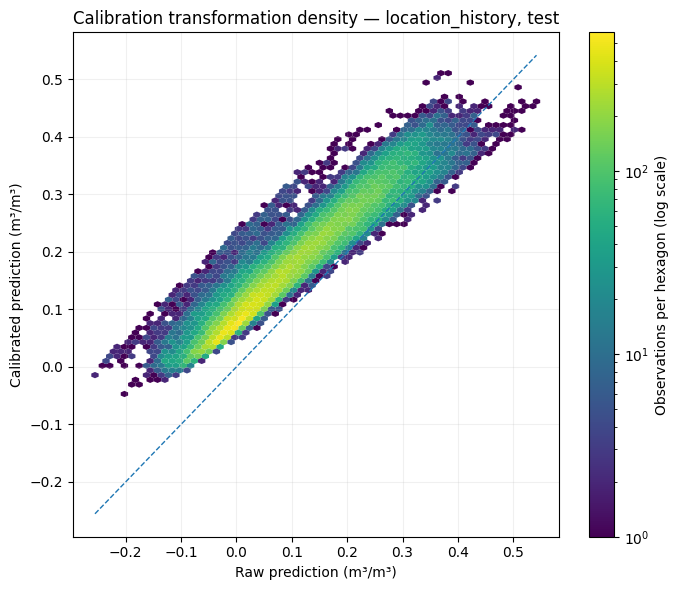

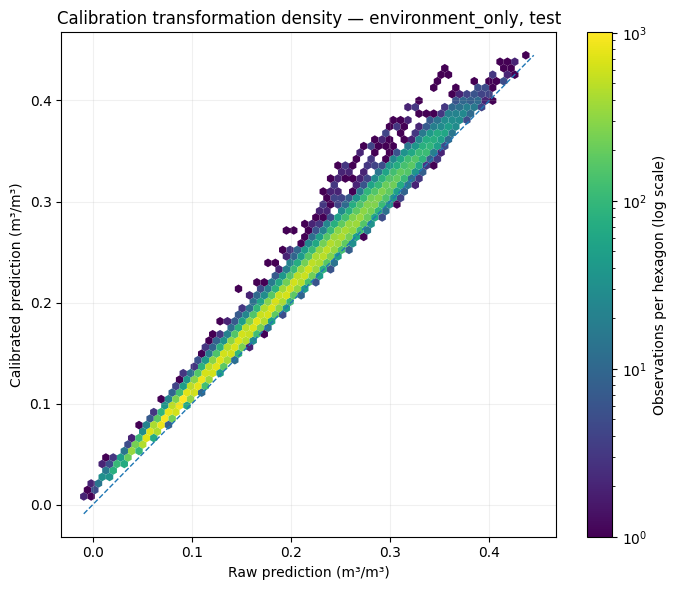

In [14]:
# 14. Calibration effects and raw-vs-calibrated density on the test sample
calibration_rows = []
for mode in ("location_history", "environment_only"):
    d = METRICS[(METRICS.task_mode == mode) & (METRICS.split == "test")].set_index("variant")
    calibration_rows.append({
        "task_mode": mode,
        "raw_mae": d.loc["raw", "mae_m3_m3"],
        "calibrated_mae": d.loc["calibrated", "mae_m3_m3"],
        "mae_change_calibrated_minus_raw": d.loc["calibrated", "mae_m3_m3"] - d.loc["raw", "mae_m3_m3"],
        "raw_rmse": d.loc["raw", "rmse_m3_m3"],
        "calibrated_rmse": d.loc["calibrated", "rmse_m3_m3"],
        "rmse_change_calibrated_minus_raw": d.loc["calibrated", "rmse_m3_m3"] - d.loc["raw", "rmse_m3_m3"],
        "calibrated_bias": d.loc["calibrated", "bias_m3_m3"],
        "anchor_rmse": d.loc["SMAP_anchor", "rmse_m3_m3"],
    })
CALIBRATION_SUMMARY = pd.DataFrame(calibration_rows)
display(CALIBRATION_SUMMARY.round(6))
CALIBRATION_SUMMARY.to_csv(TABLES_DIR / "calibration_and_anchor_comparison_test.csv", index=False)

for mode in ("location_history", "environment_only"):
    view = VIEWS[(mode, "test")]
    d = DB.execute(f"""
      SELECT raw_prediction_m3_m3, prediction_m3_m3
      FROM {view}
      WHERE isfinite(raw_prediction_m3_m3) AND isfinite(prediction_m3_m3)
      ORDER BY hash(CAST(sample_id AS VARCHAR)) LIMIT {int(PLOT_SAMPLE_PER_SPLIT)}
    """).df()
    if d.empty:
        continue
    lo = float(np.nanmin([d.raw_prediction_m3_m3.min(), d.prediction_m3_m3.min()]))
    hi = float(np.nanmax([d.raw_prediction_m3_m3.max(), d.prediction_m3_m3.max()]))
    fig, ax = plt.subplots(figsize=(7, 6))
    hb = ax.hexbin(d.raw_prediction_m3_m3, d.prediction_m3_m3,
                   gridsize=60, mincnt=1, bins="log", linewidths=0)
    fig.colorbar(hb, ax=ax, label="Observations per hexagon (log scale)")
    ax.plot([lo, hi], [lo, hi], linestyle="--", linewidth=1)
    ax.set_xlabel("Raw prediction (m³/m³)"); ax.set_ylabel("Calibrated prediction (m³/m³)")
    ax.set_title(f"Calibration transformation density — {mode}, test")
    ax.grid(alpha=0.18); fig.tight_layout()
    fig.savefig(PLOTS_DIR / f"raw_vs_calibrated_density_{mode}_test.png", dpi=180)
    plt.show(); plt.close(fig)


## 15) Automatically surface the main findings

This section prints a compact, data-derived report from the full exports. Treat it as a diagnostic lead, not as causal proof. For example, station outliers can reflect sensor issues, local representativeness, environmental covariates, data quality, or model limitations; the export alone cannot determine which explanation is correct.

In [15]:
# 15. Key findings and anomaly shortlist

def fmt_num(x, digits=5):
    try:
        return f"{float(x):.{digits}f}" if pd.notna(x) else "NA"
    except Exception:
        return str(x)

lines = []
lines.append("v19.5 ERROR ANALYSIS — AUTOMATIC SUMMARY")
lines.append(f"Target mode: {TARGET_MODE}")
lines.append("")
for split in ("train", "test"):
    lines.append(f"{split.upper()} full-split calibrated performance:")
    for mode in ("location_history", "environment_only"):
        r = METRICS[(METRICS.task_mode == mode) & (METRICS.split == split) & (METRICS.variant == "calibrated")].iloc[0]
        lines.append(f"  {mode}: n={int(r.n):,}, MAE={fmt_num(r.mae_m3_m3)}, RMSE={fmt_num(r.rmse_m3_m3)}, "
                     f"bias={fmt_num(r.bias_m3_m3)}, R²={fmt_num(r.r2)}")
    pr = PAIRED_METRICS[PAIRED_METRICS.split == split].iloc[0]
    lines.append(f"  matched rows={int(pr.n):,}; paired location−environment MAE={fmt_num(pr.location_minus_environment_mae)}; "
                 f"location win rate={fmt_num(pr.location_win_pct,2)}%")
    lines.append("")

if len(PAIRED_TEST_STATION):
    better_lh = int((PAIRED_TEST_STATION.location_minus_environment_rmse < 0).sum())
    better_eo = int((PAIRED_TEST_STATION.location_minus_environment_rmse > 0).sum())
    tied = int((PAIRED_TEST_STATION.location_minus_environment_rmse == 0).sum())
    lines.append(f"Matched test stations with >= {MIN_STATION_ROWS} rows: {len(PAIRED_TEST_STATION):,}")
    lines.append(f"  Lower station RMSE: location_history={better_lh}, environment_only={better_eo}, ties={tied}")
    lines.append("  Largest location-history gains (most negative RMSE delta):")
    for r in PAIRED_TEST_STATION.nsmallest(5, "location_minus_environment_rmse").itertuples():
        lines.append(f"    {r.network}:{r.station_id} n={r.n} ΔRMSE={fmt_num(r.location_minus_environment_rmse)}")
    lines.append("  Largest environment-only gains (most positive RMSE delta):")
    for r in PAIRED_TEST_STATION.nlargest(5, "location_minus_environment_rmse").itertuples():
        lines.append(f"    {r.network}:{r.station_id} n={r.n} ΔRMSE={fmt_num(r.location_minus_environment_rmse)}")

lines.append("")
lines.append("Interpretation reminders:")
lines.append("- Use test metrics as the primary generalisation comparison.")
lines.append("- Prefer paired metrics when judging the value of location history.")
lines.append("- Check overlap counts: a small matched subset may not represent the full test set.")
lines.append("- Investigate station/network outliers before drawing regional conclusions.")
lines.append("- Check residual sign: positive means overprediction; negative means underprediction.")
lines.append("- The notebook is diagnostic; it does not establish the cause of any error pattern.")


lines.append("")
lines.append(f"Configured review window: {EVENT_WINDOW_START.date()} to {EVENT_WINDOW_END.date()} (inclusive)")
for mode in ("location_history", "environment_only"):
    q = EVENT_EXCLUSION_METRICS[EVENT_EXCLUSION_METRICS.task_mode == mode].set_index("segment")
    if {"full_test", "outside_review_window"}.issubset(set(q.index)):
        lines.append(f"  {mode}: full RMSE={fmt_num(q.loc['full_test','rmse_m3_m3'])}; "
                     f"outside-window RMSE={fmt_num(q.loc['outside_review_window','rmse_m3_m3'])}; "
                     f"outside-window R²={fmt_num(q.loc['outside_review_window','r2'])}")
    flags = ANOMALOUS_MONTHS[(ANOMALOUS_MONTHS.task_mode == mode) & ANOMALOUS_MONTHS.is_robust_anomaly]
    lines.append(f"  {mode} robust-screen months: {list(pd.to_datetime(flags.month).dt.strftime('%Y-%m'))}")
lines.append("High-error trimming is a selective-retention sensitivity analysis, not a revised test score.")
for r in TRIM_TARGET_SUMMARY.itertuples():
    lines.append(f"  {r.task_mode}: target R²={r.target_r2:.2f}, status={r.status}, "
                 f"removed_pct={fmt_num(r.pct_test_rows_removed,2)}, retained={r.rows_retained}")

SUMMARY_TEXT = "\n".join(lines)
print(SUMMARY_TEXT)
(OUTPUT_DIR / "automatic_findings.txt").write_text(SUMMARY_TEXT, encoding="utf-8")

v19.5 ERROR ANALYSIS — AUTOMATIC SUMMARY
Target mode: direct

TRAIN full-split calibrated performance:
  location_history: n=2,216,784, MAE=0.03544, RMSE=0.04836, bias=-0.00065, R²=0.83079
  environment_only: n=2,544,038, MAE=0.05892, RMSE=0.07580, bias=0.00497, R²=0.57113
  matched rows=1,768,579; paired location−environment MAE=-0.02424; location win rate=70.11%

TEST full-split calibrated performance:
  location_history: n=905,248, MAE=0.04854, RMSE=0.06594, bias=0.00123, R²=0.65341
  environment_only: n=644,716, MAE=0.06794, RMSE=0.08626, bias=0.00405, R²=0.47046
  matched rows=182,528; paired location−environment MAE=-0.01731; location win rate=62.62%

Matched test stations with >= 10 rows: 201
  Lower station RMSE: location_history=138, environment_only=63, ties=0
  Largest location-history gains (most negative RMSE delta):
    SNOTEL:SNOTEL__Mt._Ryan n=585 ΔRMSE=-0.10383
    Ru_CFR:Ru_CFR__Fyodorovskoye_dry_spruce_stand n=419 ΔRMSE=-0.10300
    REMEDHUS:REMEDHUS__El_Coto n=574 Δ

2912

## 16) Export all analysis outputs

The outputs include the full metric tables (CSV), plots (PNG), and a machine-readable run summary. The original exports are never modified. Re-running this notebook overwrites the analysis outputs in `error_analysis_results_v19_5/` only.

In [16]:
# 16. Save a reproducibility manifest and list generated outputs
manifest = {
    "analysis_created_local": pd.Timestamp.now().isoformat(),
    "base_dir": str(BASE_DIR),
    "target_mode": TARGET_MODE,
    "export_dirs": {k: str(v) for k, v in EXPORT_DIRS.items()},
    "prediction_files": {
        mode: {split: str(folder / "predictions" / f"{split}_predictions.parquet")
               for split in ("train", "test")}
        for mode, folder in EXPORT_DIRS.items()
    },
    "settings": {
        "min_station_rows": MIN_STATION_ROWS,
        "plot_sample_per_split": PLOT_SAMPLE_PER_SPLIT,
        "spatial_grid_degrees": SPATIAL_GRID_DEGREES,
        "event_window_start": EVENT_WINDOW_START.date().isoformat(),
        "event_window_end_inclusive": EVENT_WINDOW_END.date().isoformat(),
        "trim_target_r2s": TRIM_TARGET_R2S,
        "trim_max_removal_pct": TRIM_MAX_REMOVAL_PCT,
        "cartopy_available": CARTOPY_AVAILABLE,
    },
    "tables": sorted(p.name for p in TABLES_DIR.glob("*.csv")),
    "plots": sorted(p.name for p in PLOTS_DIR.glob("*.png")),
}
(OUTPUT_DIR / "analysis_manifest.json").write_text(json.dumps(manifest, indent=2, default=str), encoding="utf-8")

print("\nANALYSIS COMPLETE")
print("Outputs:", OUTPUT_DIR)
print("CSV tables:", len(list(TABLES_DIR.glob('*.csv'))))
print("PNG plots:", len(list(PLOTS_DIR.glob('*.png'))))
print("Key files:")
for p in sorted(OUTPUT_DIR.glob("*")):
    print(" -", p.name)
print("\nDuckDB remains in memory for this notebook session. Close it with DB.close() when finished.")


ANALYSIS COMPLETE
Outputs: /home/mayur/Code/UG_SM/error_analysis_results_v19_5
CSV tables: 30
PNG plots: 68
Key files:
 - analysis_manifest.json
 - automatic_findings.txt
 - duckdb_tmp
 - plots
 - tables

DuckDB remains in memory for this notebook session. Close it with DB.close() when finished.


## How to read the most important outputs

1. **`overall_metrics.csv`** — complete train/test MAE, RMSE, bias, R², and correlation for calibrated, raw, and SMAP-anchor predictions.
2. **`paired_overlap.csv` + `paired_metrics.csv`** — the fairest overall comparison of the two model modes on exactly the same observations.
3. **`paired_station_comparison.csv`** — which stations benefit from location history and which do not.
4. **`station_metrics_all.csv`** — full per-station performance for both models and both splits.
5. **`spatial_grid_metrics_test.csv`** — coarse spatial error patterns.
6. **`monthly_metrics_test.csv`, `annual_metrics_test.csv`, `target_moisture_bin_metrics_test.csv`** — time- and moisture-dependent error patterns.
7. **`automatic_findings.txt`** — short data-derived summary and outlier shortlist.

### Suggested interpretation sequence

Start with test RMSE/MAE. Then inspect the paired comparison and the overlap percentage. Next inspect the paired station RMSE-difference map, the worst-station tables, and network summaries. Finally inspect temporal and moisture-regime plots. A model that wins overall but loses badly at a subset of stations may need targeted data-quality checks or a more careful treatment of station heterogeneity.
7. **`event_window_inclusion_exclusion_metrics.csv`** — full test score, score inside the configured late-2025 review window, and score outside it, for both models. Read this alongside `monthly_robust_anomaly_screen.csv`, `event_window_station_metrics.csv`, and `event_window_network_metrics.csv` to assess whether the spike is concentrated in a few stations or appears across the network.
8. **`high_error_trim_r2_targets.csv` + `high_error_trim_r2_curves.csv`** — how much of the highest-error test data would have to be discarded to cross R² = 0.7, 0.8, and 0.9. This is a diagnostic sensitivity calculation, not a valid replacement for the full test score. `worst_1pct_error_by_month.csv` and `worst_1pct_error_by_station.csv` show where the most severe residuals concentrate.
9. **`plots/` regional maps** — station RMSE / paired RMSE-difference maps are split into global and regional views, with small markers. Install Cartopy for country borders; without Cartopy, coordinate scatter maps are still generated but do not show political boundaries.

The default late-2025 review interval (2025-09-01 through 2025-11-30) is an investigation starting point based on the spike visible in the shared plot. It is editable in the settings cell and should not be treated as a confirmed causal event window.

10. **`zero_and_dry_target_diagnostics.csv`** — quantifies the exact-zero and near-zero observed values that form the vertical pile-up in the observed-vs-predicted plot, including what the models predict for those rows.
